# Forecasting the 2026 midterms

- AII 600: a small Senate forecast, checked against 3 November 2026. Scorecard first; each section adds one idea.
- Exercises E.1 to E.6: submit on Canvas before class on 11 November.

**Conventions**

- Margin: (Dem - Rep)%. Sections 0 to 8.
- Sections 9 to 11: Republican two-party share (switch stated in Section 9).
- Terms: glossary. As-of times: Section 0.
- Quoted numbers are printed by the code above. Simulated and made-up numbers are labeled. Seeds fixed.
- Platform facts: linked source; unread: "not verified".
- Runs on a laptop CPU in under three minutes.

| Section | Topic |
|---|---|
| G | Glossary |
| S | Scorecard: forecasts against the outcome |
| 0 | What happened on 3 November |
| 1 | How the platforms work |
| 2 | Poll averaging |
| 3 | Fundamentals |
| 4 | Blending polls and fundamentals |
| 5 | Simulation and the shared error |
| 5b | Calibration |
| 6 | Backtest on history |
| 7 | Backcast of 3 November |
| 8 | Election-night models |
| 9 | Texas governor: polls, model and market |
| 10 | Polymarket efficiency |
| 11 | Calling a race after the polls close |

**Exercises**

| Exercise | After section | Topic | Define |
|---|---|---|---|
| E.1 | 2 | Weighted poll average | `wavg` |
| E.2 | 4 | Inverse-variance blend | `w_poll`, `blend_margin` |
| E.3 | 5 | Win and control probability | `p_win`, `p_control_base`, `p_control_wide` |
| E.4 | 7 | Brier, log loss, ECE | `brier`, `logloss`, `ece5` |
| E.5 | 10 | Edge and Kelly stake | `edge`, `kelly_f` |
| E.6 | 11 | Projected final share | `share_hat` |

## Glossary

- Last column: where introduced. S = Scorecard, Top = conventions.

| Term | Meaning | In |
|---|---|---|
| Platform | Forecast publisher: Silver Bulletin, FiftyPlusOne (50+1), Decision Desk HQ (DDHQ), RealClearPolitics (RCP), New York Times (NYT), Cook Political Report (Cook), Sabato's Crystal Ball, Split Ticket, the Economist, NBC, 270toWin | S, 1 |
| Forecast | Probability (0 to 1) or seat count | S |
| Probability forecast | Chance of an event (0.75 = 3 in 4) | S, 5b |
| Chamber control | Senate: 51 of 100 (50-50 tie: Republican vice president). House: 218 of 435 | S, 0 |
| Caucus | Senators voting together. Democratic: 45 + 2 independents = 47 before | 0 |
| Special election | Fills a seat vacated early (Florida, Ohio) | 0 |
| Call | Winner projected by news organizations | 0 |
| Partial count | Votes counted so far; early counts can lean (Section 11) | 0, 9 |
| As-of time | When a number was read (Section 0) | 0 |
| Margin | (Dem - Rep)%. Sections 0 to 8 | Top |
| Two-party share | Votes / two major candidates' votes (48/(48 + 46) = 51.1%). Sections 9 to 11; 1 point of share = 2 of margin | 9 |
| SD | Standard deviation: typical distance from center (bell curve: two thirds within 1 SD) | 2 |
| Variance | SD squared | 4 |
| Poll, pollster | Survey of a voter sample; its organization | 2 |
| Sponsor | Group that paid for a poll; partisan sponsor (R, D, D/R) flagged | 2 |
| Sample size (n) | People interviewed | 2 |
| Sampling error | Random error from sampling; shrinks as n grows | 2 |
| LV, RV | Likely voters (screened); registered voters (on the rolls) | 1, 2 |
| Polling average | Weighted average of polls of one race | 2 |
| Recency weight | Weight shrinking with poll age | 2 |
| Half-life | Time for a weight to halve (7 days: a 14-day-old poll counts one quarter) | 2 |
| House effect | Pollster's habitual lean against the consensus | 2 |
| RMSE | Root mean squared error | 2 |
| Fundamentals | Pre-poll information: lean, incumbency, national mood | 3 |
| Partisan lean | Last presidential margin of the state | 3b |
| National environment | National mood moving all races one way | 3 |
| Generic ballot | Poll: which party for Congress | 3a |
| Incumbency, open seat | Sitting senator running; no incumbent running | 3c |
| Appointee | Appointed, never elected; coded open | 3c, 7 |
| Midterm penalty | Midterm loss of the president's party; coefficient of `backlash` | 3c |
| Regression, coefficient | Fitted line; points moved per unit of a predictor | 3 |
| Residual, residual SD | Actual - predicted; its typical size | 3 |
| Inverse variance | 1 / variance, the weight of an estimate | 4 |
| Blend weight | Share of the blend from polls | 4 |
| Monte Carlo, draw | Repeat a random experiment, count outcomes; one run | 5 |
| Student-t, df | Fat-tailed bell curve; smaller df, fatter tails | 5 |
| Shared (national) error | Miss common to all races in a year | 3c, 5 |
| Correlation, rho | Races missing together; rho = shared share of error variance | 5 |
| Seat distribution | Share of simulations at each seat count | 5 |
| Control probability | Share of simulations reaching control | 5 |
| Out-of-sample | Data not used in the fit | 5b |
| Calibration | Of events given p, a fraction p happen | 5b |
| Brier score | Mean (p - y)². 0 perfect, 0.25 coin flip | S, 5b |
| Log loss | Mean -log(probability of what happened) | 5b |
| Backtest | Method run on past elections | 6 |
| Leave-one-year-out | Predict each year from the other years | 6 |
| Interval coverage | Share of results inside a stated interval | 6 |
| Backcast | Pre-event forecast rebuilt after the event, then scored | 7 |
| Rating labels | Solid, Likely, Lean, Toss-up (no edge) | S, 7 |
| Rating tally | Seats by rating label, toss-ups unassigned; not a forecast | S |
| Prediction market | Contracts paying $1 if the event happens | S, 10 |
| Polymarket, Kalshi | The two markets used | S, 10 |
| Price as probability | 0.70 = 70% | S, 10 |
| Martingale | Expected next value = current value | 10 |
| Efficient market | Prices reflect all public information | 10 |
| Bayes factor | P(outcome) by A / P(outcome) by B; above 1 favors A | 10 |
| Kelly stake | Wealth share to bet for fastest long-run growth | 5b, 10 |
| Herding | Pollsters nudging toward other polls | 9 |
| Needle | NYT live election-night gauge | 1, 8 |
| Expected vote | Votes an area is expected to cast | 8 |
| Reporting order | Order areas report counts | 8 |
| Swing | Change in a party's share since last election | 8, 11 |
| Precinct, county | Smallest voting area (one polling place); group of precincts | 8, 11 |
| Tukey's method | NBC, 1960s to 1980: each counted group's swing applied to its precincts still out | 11 |
| Jackknife | Recompute leaving out one group at a time; spread = uncertainty | 11 |
| Anytime-valid boundary | Call when P(win) ≥ 1 - alpha; error rate holds however often you look | 11 |

### Setup

- Packages and plot style. Blue = Democratic, red = Republican.

In [ ]:
import io
import warnings
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf   # linear regression with formulas
from scipy import stats                  # Student-t and normal distributions

warnings.filterwarnings("ignore")        # hide library warnings

BLUE, RED, GREY = "#1f5fa8", "#c0392b", "#666666"
plt.rcParams.update({"figure.figsize": (6.4, 3.8), "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

from IPython.display import display

def show_table(df, index=True):
    """Display a table as a formatted HTML table."""
    if isinstance(df, pd.Series):
        df = df.to_frame()
    st = df.style.format(lambda v: "" if (isinstance(v, float) and v != v) else (f"{v:g}" if isinstance(v, float) else v))
    if not index:
        st = st.hide(axis="index")
    display(st)


- Downloads six data files to `data` (once).
- `senate_1976_2024.tab`: statewide Senate general-election results, 1976 to 2024, one row per candidate. MIT Election Data and Science Lab, <https://doi.org/10.7910/DVN/PEJ5QU>, CC0.
- `president_1976_2024.csv`: presidential results by state, 1976 to 2024. MIT Election Data and Science Lab, <https://doi.org/10.7910/DVN/42MVDX>, CC0.
- `generic_topline_historical.csv`: daily generic ballot averages, 1995 to November 2016. FiveThirtyEight, <https://github.com/fivethirtyeight/data/tree/master/congress-generic-ballot>, CC BY 4.0.
- `elections_backcast.csv`, `elections_platforms.csv`: 2026 race and platform tables I assembled (Section 7).
- `elections_polls_final.csv`: 205 final polls in 27 Senate races, ended 13 October to 2 November 2026; one row per poll, `source_url` per row (Wikipedia race pages). Sections 2 and 7.

In [ ]:
DATA = Path("data")
DATA.mkdir(exist_ok=True)
BASE = "https://vsokolov.org/courses/files/600/data"   # course data folder
for name in ("senate_1976_2024.tab", "president_1976_2024.csv", "generic_topline_historical.csv",
             "elections_backcast.csv", "elections_platforms.csv", "elections_polls_final.csv"):
    path = DATA / name
    if not path.exists():                                # download only once
        urlretrieve(f"{BASE}/{name}", path)

- `bc`: one row per Senate race (35): call, 2024 presidential margin, mean final poll margin and number of polls where found.
- `pf`: one row per platform forecast or result snapshot, with date.
- `pl`: one row per final poll (205): pollster, sponsor, dates, sample size, D and R shares.

In [3]:
bc = pd.read_csv(DATA / "elections_backcast.csv")    # 2026 Senate races
pf = pd.read_csv(DATA / "elections_platforms.csv")   # platform forecasts and snapshots
pl = pd.read_csv(DATA / "elections_polls_final.csv", parse_dates=["start", "end"])   # final polls, 27 races
# drop clock times from text columns; keep dates
TIME = r"\s*\(?\d{1,2}:\d{2}(\s?[AaPp]\.?[Mm]\.?)?(\s?E[SD]?T)?\)?"
for col in pf.select_dtypes("object"):
    pf[col] = pf[col].str.replace(TIME, "", regex=True).str.replace(r"\s+as of\s+", " ", regex=True)
print(f"Race table: {len(bc)} rows | platform table: {len(pf)} rows | polls: {len(pl)} in {pl.state.nunique()} races")

Race table: 35 rows | platform table: 25 rows | polls: 205 in 27 races


- `FACTS`: election-night facts quoted in Section 0, with sources (Ballotpedia about 9:05 AM ET, Wikipedia 10:10 AM EST, 4 November). Seat arithmetic at the bottom.

In [4]:
FACTS = dict(
    # Ballotpedia, Senate results page (about 9:05 AM ET, 4 Nov)
    n_up=35,              # seats up: 33 regular + FL, OH specials
    d_won=20, r_won=13,   # races won (Ballotpedia)
    uncalled=2,           # uncalled (both R-held)
    flips=7,              # seats that changed party, all to Democrats
    pre_r=53, pre_d=45, pre_i=2,   # Senate before: R, D, independents caucusing with D
    need=51,              # control; 50-50 tie goes to the R vice president
    # Ballotpedia, House page (about 9:05 AM ET, 4 Nov)
    h_d=211, h_r=122, h_unc=102,    # House: D, R, uncalled (of 435)
    h_flips=23,                     # House flips so far, all to D
    # Wikipedia, 2026 Senate and House pages (10:10 AM EST, 4 Nov)
    w_h_d=231, w_h_r=139, w_declared=85.1,          # House: D, R, percent declared
    w_s_di=54, w_s_r=44, w_s_tbd=2,                 # Senate: D caucus, R, undecided (AK, MS)
)
# Seat arithmetic: D caucus = 45 + 2 = 47.
# 13 D seats up, so 47 - 13 = 34 not up.
FACTS["d_up"] = 13
FACTS["d_safe"] = FACTS["pre_d"] + FACTS["pre_i"] - FACTS["d_up"]       # 34 seats not up
FACTS["d_needed_of_35"] = FACTS["need"] - FACTS["d_safe"]               # 51 - 34 = 17 wins needed among the 35
print("Senate seats up:", FACTS["n_up"], "| Democratic-caucus seats not up:", FACTS["d_safe"],
      "| Democratic wins needed among the 35:", FACTS["d_needed_of_35"])

Senate seats up: 35 | Democratic-caucus seats not up: 34 | Democratic wins needed among the 35: 17


- `check(name, value, expected, ndigits)`: rounds your value, compares with a stored hash. Prints `ok` or `not yet` (not an error).

In [ ]:
from hashlib import sha256


def check(name, value, expected, ndigits=3):
    """Print ok if value, rounded to ndigits decimals, matches the stored reference value; otherwise print not yet."""
    if value is None:
        print(f"not yet  {name}: still None")
        return
    try:
        v = float(value)
    except (TypeError, ValueError):
        print(f"not yet  {name}: must be a single number, not {type(value).__name__}")
        return
    if not np.isfinite(v):
        print(f"not yet  {name}: not finite (nan or inf)")
        return
    s = f"{round(v, ndigits):.{ndigits}f}"
    got = sha256(f"aii600-elections|{name}|{s}".encode()).hexdigest()[:16]
    print(f"ok       {name}" if got == expected else f"not yet  {name}: you got {s}; check the formula and the inputs")

## Scorecard: forecasts against the outcome

- Election-eve forecasts against the 3 November outcome: chamber control, Senate seats, races, Texas governor. Our numbers come from Sections 7 and 9, which stop with an error if they no longer match.

**Terms**

- Chamber: Senate or House. Control: majority of its seats.
- Brier score: $(p-y)^2$, $y=1$ if the event happened. 0 perfect, 0.25 coin flip, lower better.
  - Example: a forecaster gives the Democrat 80%.
    - Democrat wins ($y=1$): $(0.8-1)^2 = 0.04$.
    - Democrat loses ($y=0$): $(0.8-0)^2 = 0.64$.
  - Over many races, average the scores.
  - Why Brier: saying what you believe scores best. You think 70%:
    - say 70%: expected score 0.7(0.3)² + 0.3(0.7)² = 0.21
    - say 100%: 0.7(0)² + 0.3(1)² = 0.30
    - say 50%: 0.25
  - Lower is better, so 70% wins. Saying 100% or 50% when you believe 70% gives a worse score. If you believe 100%, saying 100% scores 0 and saying 70% scores 0.09. The best report is always your own belief. A score with this property is called proper.
- Rating to probability (my mapping, Section 7): Solid 0.97, Likely 0.85, Lean 0.70, Toss-up 0.50; a Republican label gives $1-p$.
- Seat miss: forecast $-$ observed. Texas Brier: $P(\text{Abbott})^2$ ($y=0$ on the partial count).
- Rating tally: races added by label, toss-ups unassigned. Not a seat forecast.
- Seat forecast: simulation median or mean.
- Market price = probability (0.755 = 75.5%). Markets: Polymarket, Kalshi.

**Rules**

- Election-eve forecasts only.
- Market prices: Polson and Sokolov, "Are Polymarket Odds Efficient?" (citing RotoWire). Kalshi's probability is backed out of its reported Brier score $B$ (event happened): $p = 1-\sqrt{B}$.
- As-of times: Section 0. Tables repeat a time where the source gives one.
- Control: one event per chamber. One outcome cannot rank forecasters, so no score.
- Seats: only true seat forecasts scored. Rating tallies listed, not scored.
- Races: our model and the ratings scored on the same races.
- Texas: outcome is a partial count, so every Texas score is provisional.

In [6]:
# Election-eve forecasts against the outcome.
# Platforms: platform and race tables. Markets: Polson and Sokolov,
# "Are Polymarket Odds Efficient?" (RotoWire); Kalshi backed out of its Brier score.
# OUR numbers: computed and checked in Sections 7 and 9.
OURS = dict(senate_pD=0.938, senate_seats=53.9, race_brier33=0.041, race_brier31=0.041, tx_abbott=0.744)
MKT = dict(poly_senate=0.755, poly_house=0.945, kalshi_senate=1 - np.sqrt(0.0625), kalshi_house=1 - np.sqrt(0.0045))

# Chamber control: one event each, so no score.
ctrl = pd.DataFrame([
    ("Senate control", "FiftyPlusOne (final run, 3 Nov)", float(pf[pf.platform.str.startswith("50+1") & pf.date.astype(str).str.startswith("2026-11-03")].senate_pD.iloc[0])),
    ("Senate control", "This notebook (Section 7)", OURS["senate_pD"]),
    ("Senate control", "Polymarket (6 PM ET, 3 Nov)", MKT["poly_senate"]),
    ("Senate control", "Kalshi (time not given)", MKT["kalshi_senate"]),
    ("House control", "Polymarket (6 PM ET, 3 Nov)", MKT["poly_house"]),
    ("House control", "Kalshi (time not given)", MKT["kalshi_house"]),
], columns=["question", "forecaster", "P(Democrats)"])
ctrl["outcome"] = "D"
print("Chamber control (Democrats won both).  One event cannot rank forecasters, so no score is shown:")
show_table(ctrl.round(3), index=False)

# Senate seats: election-eve numbers (leading integer) against the observed count.
# Score only simulation medians or means; rating tallies leave toss-ups unassigned.
eve = pf[pf.date.astype(str).str.startswith(("2026-11-02", "2026-11-03")) & pf.senate_seats_D.notna()].copy()
eve["seats_D"] = eve.senate_seats_D.astype(str).str.extract(r"^(\d+)")[0].astype(float)
eve["kind"] = np.where(eve.senate_seats_D.astype(str).str.contains("median"), "forecast median", "rating tally")
OBS_SEATS = FACTS["w_s_di"]                      # D caucus seats; 2 undecided are R-held
fc_seats = pd.concat([eve[eve.kind == "forecast median"][["platform", "seats_D"]],
                      pd.DataFrame([{"platform": "This notebook (Section 7, mean)", "seats_D": OURS["senate_seats"]}])])
fc_seats["miss"] = fc_seats.seats_D - OBS_SEATS
print(f"\nSenate seats for the Democratic caucus: observed {OBS_SEATS} at 10:10 AM EST on 4 Nov ({FACTS['w_s_tbd']} undecided, both Republican-held).")
print("True seat forecasts (scored; a median and a mean are different summaries of a seat distribution):")
show_table(fc_seats, index=False)
tally = eve[eve.kind == "rating tally"].sort_values("seats_D")
tally["platform"] = tally.platform.where(tally.platform != "Silver Bulletin", "Silver Bulletin (ratings row)")
print("Rating tallies, toss-ups not assigned (not forecasts, so not scored; each is a lower bound on the seats a party could win):")
show_table(tally[["platform", "senate_seats_D"]].rename(columns={"senate_seats_D": "tally and note"}), index=False)

# Races: ratings as probabilities (our mapping), on called races.
# Ratings cover 31 of 33 (FL, OH unrated); our model scored on the same 31.
LEVEL = {"solid": .97, "safe": .97, "likely": .85, "lean": .70}
def label_p(s):
    if pd.isna(s): return np.nan
    t = s.lower().replace("(flip)", "").strip()
    if t.startswith("toss"): return .5
    lev, party = t.split(); return LEVEL[lev] if party == "d" else 1 - LEVEL[lev]
cr = bc[bc.called.isin(["D", "R"])]; yD = (cr.called == "D").astype(float)
n31 = int(cr["silver_rating"].notna().sum())
race = pd.DataFrame([(name, int(cr[col].notna().sum()), np.nanmean((cr[col].map(label_p) - yD) ** 2))
                     for name, col in [("Silver Bulletin rating", "silver_rating"), ("FiftyPlusOne rating", "fpo_rating"),
                                       ("DDHQ rating", "ddhq_rating"), ("Cook rating", "cook_rating"), ("RCP rating", "rcp_rating")]]
                    + [("This notebook (Section 7), same 31 races", n31, OURS["race_brier31"]), ("Always 50%", n31, .25)],
                    columns=["forecaster", "races", "Brier"])
print("\nCalled Senate races, Brier score on the same 31 races (lower is better):")
show_table(race.round(3), index=False)
print(f"On all {len(cr)} called races our Brier score is {OURS['race_brier33']:.3f}; that is not comparable with the ratings.")

# Texas: all favored Abbott. PROVISIONAL: outcome is the partial count of
# 9:13 PM ET, 3 November; Hinojosa leads (Section 9).
tx_fc = pd.DataFrame({"P(Abbott)": {"This notebook, Kalman poll model (Section 9)": OURS["tx_abbott"],
                                    "Polymarket (5:13 PM CT, 3 Nov)": .663, "Kalshi (time not given)": .60}})
tx_fc["Brier (provisional)"] = tx_fc["P(Abbott)"] ** 2
print("\nTexas governor, PROVISIONAL scores (outcome: Hinojosa leads the partial count of 9:13 PM ET, 3 Nov).")
print("The Brier score is computed from the rounded probability shown, so it can differ by 0.001 from Section 10:")
show_table(tx_fc.round(3), index=True)


Chamber control (Democrats won both).  One event cannot rank forecasters, so no score is shown:


question,forecaster,P(Democrats),outcome
Senate control,"FiftyPlusOne (final run, 3 Nov)",0.79,D
Senate control,This notebook (Section 7),0.938,D
Senate control,"Polymarket (6 PM ET, 3 Nov)",0.755,D
Senate control,Kalshi (time not given),0.75,D
House control,"Polymarket (6 PM ET, 3 Nov)",0.945,D
House control,Kalshi (time not given),0.933,D



Senate seats for the Democratic caucus: observed 54 at 10:10 AM EST on 4 Nov (2 undecided, both Republican-held).
True seat forecasts (scored; a median and a mean are different summaries of a seat distribution):


platform,seats_D,miss
50+1 (FiftyPlusOne),53,-1
"This notebook (Section 7, mean)",53.9,-0.1


Rating tallies, toss-ups not assigned (not forecasts, so not scored; each is a lower bound on the seats a party could win):


platform,tally and note
RCP,"47 (rating-based, 9 tossups)"
"Ratings, Cook",48 (6 tossups)
DDHQ,"49 (rating-based, 6 tossups)"
"Ratings, Economist",49 (4 tossups)
Silver Bulletin (ratings row),"52 (rating-based, 2 tossups)"
270toWin consensus,52 (50 D + 2 I; 46 R; 2 unrated)
"Ratings, Sabato",53
"Ratings, Split Ticket",53 (1 tossup)



Called Senate races, Brier score on the same 31 races (lower is better):


forecaster,races,Brier
Silver Bulletin rating,31,0.035
FiftyPlusOne rating,31,0.035
DDHQ rating,31,0.044
Cook rating,31,0.062
RCP rating,31,0.066
"This notebook (Section 7), same 31 races",31,0.041
Always 50%,31,0.25


On all 33 called races our Brier score is 0.041; that is not comparable with the ratings.

Texas governor, PROVISIONAL scores (outcome: Hinojosa leads the partial count of 9:13 PM ET, 3 Nov).
The Brier score is computed from the rounded probability shown, so it can differ by 0.001 from Section 10:


,P(Abbott),Brier (provisional)
"This notebook, Kalman poll model (Section 9)",0.744,0.554
"Polymarket (5:13 PM CT, 3 Nov)",0.663,0.44
Kalshi (time not given),0.6,0.36


**Verdict**

- **Direction: right.** Every probability forecast favored Democrats in both chambers.
  - Senate control: 0.750 (Kalshi) to 0.938 (ours).
  - House control: 0.933 (Kalshi), 0.945 (Polymarket).
- **Control: no ranking.** One outcome per chamber cannot rank forecasters.
  - Our 0.938 is probably overconfident: shared error about 1.2 points in polled races (rho 0.08) against a year-level SD of 6.45 points in the Section 6 backtest. Section 6 calls the Section 5 shared error a lower estimate.
- **Seats: close.** 50+1 median 53 and our mean 53.9: within 1 seat of the 54 Democratic-caucus seats.
  - Rating tallies (47 to 53): not forecasts, toss-ups unassigned, so lower bounds; not scored.
- **Races: between the best and the rest.** Same 31 races, Brier: Silver Bulletin and FiftyPlusOne 0.035, our model 0.041, DDHQ 0.044, Cook 0.062, RCP 0.066, coin flip 0.250.
- **Texas governor: provisional.** All forecasts favored Abbott (0.600 to 0.744); Hinojosa leads the partial count of 9:13 PM ET, 3 November.
  - Early counts are biased (Section 11); scores can change with the final count.
  - Paper's caveat: "if Abbott's final two party share is 46%, the error is 1.4 market sd and 2.2 model sd; the ranking of forecasts is unchanged for any final share below 50%."
  - On the partial count: markets least wrong; our poll model most confident and most wrong.
- **Overall.** The error most often left out is the shared one (Section 5).

## 0. What happened on 3 November

**Sources and as-of times** (counts still moving; nothing final)

| Number | Source | As of |
|---|---|---|
| Senate and House counts | Ballotpedia ([Senate results](https://ballotpedia.org/Election_results,_2026:_U.S._Senate), [House page](https://ballotpedia.org/United_States_House_of_Representatives_elections,_2026)) | about 9:05 AM ET, 4 November |
| Senate and House counts, Alaska and Mississippi undecided | Wikipedia ([2026 Senate elections](https://en.wikipedia.org/wiki/2026_United_States_Senate_elections), [2026 House elections](https://en.wikipedia.org/wiki/2026_United_States_House_of_Representatives_elections)) | 10:10 AM EST, 4 November |
| Texas governor partial count | Polson and Sokolov, "Are Polymarket Odds Efficient?" | 9:13 PM ET, 3 November |
| Polymarket Senate and House control prices | same paper | 6 PM ET, 3 November |
| Polymarket Texas governor prices | same paper | 0.618 at 7:50 AM CT and 0.663 at 5:13 PM CT, 3 November (before Texas polls closed) |
| Kalshi probabilities | same paper, citing RotoWire | no time given in the source |

- House counts differ: read at different times.

**Senate**

- 35 seats up: 33 regular + Florida and Ohio specials.
- Before: 53 R, 45 D, 2 independents caucusing with Democrats.
- Control: 51 seats (a tie goes to the Republican vice president).
- Ballotpedia: 20 D, 13 R, 2 uncalled (both Republican-held, not named). 7 flips, all to Democrats.
- Wikipedia: Democratic caucus 54, Republicans 44, 2 undecided (Alaska, Mississippi). I use this list of uncalled races.
- Democratic caucus: 34 seats not up ($45 + 2 - 13$); needs 17 of the 35 to reach 51 ($51 - 34$).

**House**

- Control: 218 of 435.
- Ballotpedia: 211 D, 122 R, 102 uncalled.
- Wikipedia: 231 D, 139 R, 85.1% of races declared.
- National House popular vote: not available.

**Race-level data**

- Calls: `elections_backcast.csv`, by hand from the Wikipedia 2026 Senate page. No vote shares yet: Section 7 scores calls, not margins.

In [7]:
bcs = bc.copy()
bcs["po"] = bcs.state.str.replace(" (special)", "", regex=False)
called = bcs[bcs.called.isin(["D", "R"])]
unc = bcs[~bcs.called.isin(["D", "R"])]
gains = called[(called.called == "D") & (called.incumbent_party == "R")]
print(f"Races in the table: {len(bcs)}; called: {len(called)} (D {int((called.called == 'D').sum())}, R {int((called.called == 'R').sum())}); uncalled: {', '.join(unc.po)}")
print(f"Seats the Democrats gained from Republicans among called races: {len(gains)} ({', '.join(gains.po)})")
print(f"Seats the Republicans gained: {len(called[(called.called == 'R') & (called.incumbent_party == 'D')])}")
print(f"Rows with a vote margin reported: {int(bcs.result_margin.notna().sum())}")

Races in the table: 35; called: 33 (D 20, R 13); uncalled: Alaska, Mississippi
Seats the Democrats gained from Republicans among called races: 7 (Ohio, Iowa, Kansas, Maine, North Carolina, South Carolina, Texas)
Seats the Republicans gained: 0
Rows with a vote margin reported: 0


## 1. How the platforms work

- All blend polls and structure, then simulate; weights and error models differ. "Not verified": primary page not readable.
- Error levels: national, chamber, regional, state, cluster (similar districts), race.

| | Silver Bulletin (FLIPR) | FiftyPlusOne | New York Times | RealClearPolitics | Decision Desk HQ |
|---|---|---|---|---|---|
| Poll averaging | Recency, sample size, pollster rating; house effects; trends; likely-voter adjustment. [1] | Decay about 3%/day, 14%/day in the final two weeks; house effects shrunk to zero; no synthetic or model-derived polls. [2] | Not verified. [3] | Simple average, no house effects (prior practice, not verified for 2026). [4] | Generic ballot average; details not read. [5] |
| Fundamentals | Regression: lean, national environment, incumbency, fundraising, experience, scandals. [1] | Regularized logistic regression, 20 years: lean (last two presidential results), incumbency, experience, fundraising. [2] | Not verified. | None found. | Partisan baseline, national environment, incumbency, presidential-party cycle, campaign finance; varies by race. [5] |
| Blend | Classic: polls + fundamentals; Deluxe (default) adds expert ratings; fundamentals down-weighted when they disagree with polls. [1] | Stacks polls, fundamentals, ratings by out-of-sample error; Senate leans on polls near Election Day. [2] | Needle: pre-election expectation + returns. [3] | None. | Race-level. One Rhode Island Senate page: 70% fundamentals, 5% polls, 25% prediction markets. [5] |
| Uncertainty | Race, state, national; slightly fat tails; grows with fewer polls, more undecideds. [1] | National, chamber, regional, race (state, cluster: House only); Student-t, about 10 df. [2] | Not verified. | None found. | Not verified. |
| Simulations | 40,000 per update. [1] | 40,000 per run. [2] | Needle: live estimate from returns. [3] | None. | Not verified. |

**Sources**

1. Silver Bulletin: <https://www.natesilver.net/p/flipr-midterms-model-methodology>, <https://www.natesilver.net/p/nate-silver-2026-midterm-election-polls-model>.
2. FiftyPlusOne: <https://blog.fiftyplusone.news/p/2026-forecast-methodology>, launch post <https://blog.fiftyplusone.news/p/election-forecast-democrats-strongly-favored-house-tilt-senate>.
3. NYT needle, secondary account (snippet only; NYT page not fetched): <https://reutersinstitute.politics.ox.ac.uk/news/moving-needle-how-new-york-times-aims-guide-readers-through-americas-most-uncertain-election>. NYT 2026 polling-average method not verified.
4. RealClearPolling: access error, method not read: <https://www.realclearpolling.com>. Simple average: earlier RCP practice, not verified for 2026.
5. DDHQ press release, 15 July 2026: <https://ddhq.io/press/decision-desk-hq-releases-2026-congressional-forecast-model> (indicators: generic ballot, presidential approval; uses Kalshi and Polymarket data). Race blends: snippets of <https://votes.decisiondeskhq.com>. Methodology page rate limited, not read.

**Next**: poll average, fundamentals, inverse-variance blend, simulation with a shared error.

## 2. Poll averaging

- Two averages of the same polls can differ by a point or more: which polls count, their weights, pollster bias removal.

**Data**

- Real: Maine's 14 final polls in `pl` (ended 14 October to 2 November 2026), margin $m_j = D - R$ in points. Only the call is known for Maine (no published margin), so real polls cannot be scored for accuracy.
- Simulated: a made-up race, true margin $m^* = +2.0$, 2,000 repeats; shows which average misses least. Labeled below.

**Notation**

- $m_j$: margin of poll $j$ (points). $a_j$: age (days from poll end date to 3 November). $n_j$: sample size. $J$: number of polls.
- $q_j$: pollster quality, 0 to 1 (real polls: $q_j = 1$, no ratings used). $h_f$: house effect of pollster $f$.
- Sponsor: group that paid for the poll. Partisan sponsor (R, D, D/R): flagged, not removed.
- Marist's sample size is blank in the source: set to the median $n$ of the other Maine polls.

**Averages**

1. Simple: $\bar m = \frac{1}{J}\sum_j m_j$. This is the Section 7 poll input.
2. RCP style: latest poll per pollster, equal weights.
3. Weighted: $w_j = q_j \sqrt{n_j / 600}\; 0.5^{a_j / 7}$ (600: reference size; half-life 7 days). Average $\bar m_w = \sum_j w_j m_j / \sum_j w_j$.
4. Weighted with house effects, repeated three times:
   - $h_f = \frac{k_f}{k_f + 2}\,\overline{(m_j - \bar m_w)}$, mean over the $k_f$ polls by $f$.
   - Center the $h_f$ to mean zero (assumes biases cancel).
   - Subtract $h_f$ from each poll, $m_j' = m_j - h_{f(j)}$; re-average: $\bar m_w' = \sum_j w_j m_j' / \sum_j w_j$.
5. Without partisan sponsors: simple mean of the polls with no sponsor.

- Functions `rcp_avg`, `weights`, `weighted_avg` (reused by E.1 and the simulation below). Maine's polls, the five averages, a plot.

REAL polls, Maine: 14 polls from 14 pollsters, 6 with a partisan sponsor


pollster,sponsor,end,n,margin,age,weight share,house effect
InsiderAdvantage,R,2026-10-14,1200,2,20,0.02,-0.6
Beacon Research/ Shaw & Co. Research,D/R,2026-10-20,1514,0,14,0.04,-1.26
Trafalgar Group,R,2026-10-23,1077,0,11,0.04,-1.26
Echelon Insights,R,2026-10-23,413,7,11,0.03,1.07
Marist University,,2026-10-25,,2,9,0.05,-0.6
SSRS,,2026-10-26,783,4,8,0.05,0.07
Data for Progress,D,2026-10-27,652,5,7,0.05,0.4
YouGov,,2026-10-29,1503,5,5,0.09,0.4
University of New Hampshire,,2026-10-31,1654,9,3,0.12,1.74
Emerson College,,2026-11-01,600,-2,2,0.08,-1.93


Simple mean of all polls (Section 7 input)      3.79
RCP style (latest per pollster)                 3.79
Weighted                                        4.34
Weighted + house effects                        4.15
Without partisan sponsors (8 polls)             4.50


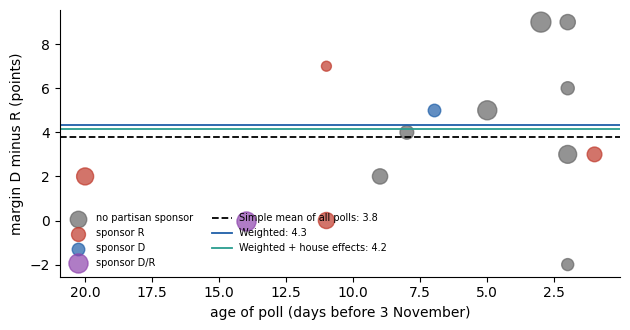

In [8]:
def rcp_avg(d):
    """Average of the most recent poll from each pollster, equal weights."""
    last = d.sort_values("age").groupby("pollster").head(1)
    return last.margin.mean()


def weights(d):
    """Poll weight: quality x sqrt(sample size / 600) x 0.5 ** (age / 7), so it halves every 7 days."""
    return d.quality * np.sqrt(d.n / 600) * 0.5 ** (d.age / 7)


def weighted_avg(d, adjust=False, return_h=False):
    w = weights(d)
    avg = (w * d.margin).sum() / w.sum()
    if not adjust:
        return avg
    for _ in range(3):
        # house effect: shrunk mean deviation, k / (k + 2)
        dev = (d.margin - avg).groupby(d.pollster).mean()
        k = d.groupby("pollster").size()
        h = dev * k / (k + 2)
        h = h - h.mean()   # center across pollsters
        adj = d.margin - h.reindex(d.pollster).values
        avg = (w * adj).sum() / w.sum()
    return (avg, h) if return_h else avg


# REAL polls: Maine, final polls ended 14 October to 2 November 2026 (Wikipedia race page)
mep = pl[pl.state == "Maine"].copy()
mep["margin"] = mep.dem - mep.rep                               # D minus R, points
mep["age"] = (pd.Timestamp("2026-11-03") - mep.end).dt.days     # days before the election
mep["n_raw"] = mep.n                                            # keep the blank sample size for display
mep["n"] = mep.n.fillna(mep.n.median())                         # Marist: median of the others
mep["quality"] = 1.0                                            # no pollster ratings used
avg_he, h_f = weighted_avg(mep, adjust=True, return_h=True)
w_m = weights(mep)
n_free = int(mep.sponsor.isna().sum())
res = {"Simple mean of all polls (Section 7 input)": mep.margin.mean(),
       "RCP style (latest per pollster)": rcp_avg(mep),
       "Weighted": weighted_avg(mep),
       "Weighted + house effects": avg_he,
       f"Without partisan sponsors ({n_free} polls)": mep[mep.sponsor.isna()].margin.mean()}
print(f"REAL polls, Maine: {len(mep)} polls from {mep.pollster.nunique()} pollsters, {int(mep.sponsor.notna().sum())} with a partisan sponsor")
tbl = pd.DataFrame({"pollster": mep.pollster, "sponsor": mep.sponsor.fillna(""), "end": mep.end.dt.strftime("%Y-%m-%d"),
                    "n": mep.n_raw, "margin": mep.margin, "age": mep.age, "weight share": w_m / w_m.sum(),
                    "house effect": h_f.reindex(mep.pollster).values}).sort_values("age", ascending=False)
show_table(tbl.round(2), index=False)
for k, v in res.items():
    print(f"{k:46s} {v:5.2f}")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for lab, c, mask in (("no partisan sponsor", GREY, mep.sponsor.isna()), ("sponsor R", RED, mep.sponsor == "R"),
                     ("sponsor D", BLUE, mep.sponsor == "D"), ("sponsor D/R", "#8e44ad", mep.sponsor == "D/R")):
    ax.scatter(mep.age[mask], mep.margin[mask], s=mep.n[mask] / 8, color=c, alpha=0.7, label=lab)
for (lab, v), c in zip([kv for i, kv in enumerate(res.items()) if i in (0, 2, 3)], ("black", BLUE, "#2a9d8f")):
    ax.axhline(v, color=c, lw=1.3, ls="--" if c == "black" else "-", label=f"{lab.split(' (')[0]}: {v:.1f}")
ax.invert_xaxis(); ax.set_xlabel("age of poll (days before 3 November)"); ax.set_ylabel("margin D minus R (points)")
ax.legend(fontsize=7, frameon=False, ncol=2, loc="lower left")
plt.tight_layout(); plt.show()

**Simulated** (made-up race, true margin $m^* = +2.0$; not Maine): 2,000 repeats, new sampling noise, same design of 14 polls by 6 pollsters.

- Poll: $m_j = m^* + h_{f(j)} + \varepsilon_j$, $\varepsilon_j \sim N(0, \sigma_j^2)$, $\sigma_j = 100\sqrt{0.95/n_j}$ (margin sampling SD, both candidates near 48%).
- Mean error: $\frac{1}{R}\sum_r (\hat m_r - m^*)$, the bias. RMSE: $\sqrt{\frac{1}{R}\sum_r (\hat m_r - m^*)^2}$, the typical miss. $R = 2000$.

In [9]:
# SIMULATED polls for a MADE-UP race.  True margin and house effects are made up.
TRUE = 2.0   # true margin of the made-up race (D minus R, points)
# true house effect of each pollster in points; they sum to zero
HOUSE_TRUE = {"A": 0.0, "B": 1.0, "C": -1.0, "D": 0.0, "E": -4.0, "F": 4.0}
# pollster quality score q (made up)
QUALITY = {"A": 1.0, "B": 1.0, "C": 0.8, "D": 0.8, "E": 0.6, "F": 0.6}
# poll schedule: pollster, age (days), n (made up)
DESIGN = pd.DataFrame({
    "pollster": list("AAABBCCDDEEEFF"),
    "age": [2, 10, 24, 6, 20, 4, 18, 9, 27, 1, 3, 8, 2, 14],
    "n": [800, 700, 900, 600, 650, 500, 800, 1000, 600, 400, 450, 500, 450, 500],
})


def draw_polls(rng):
    """Simulate the margin in each poll: truth + house effect + sampling noise."""
    d = DESIGN.copy()
    d["house"] = d.pollster.map(HOUSE_TRUE)
    d["quality"] = d.pollster.map(QUALITY)
    sd = 100 * np.sqrt(0.95 / d.n)  # margin sampling SD, both near 48%
    d["margin"] = TRUE + d.house + rng.normal(0, sd)
    return d


# 2,000 repeats; each method's error
rng = np.random.default_rng(11)
errs = {"RCP": [], "Weighted": [], "Weighted + HE": []}
for _ in range(2000):
    d = draw_polls(rng)
    errs["RCP"].append(rcp_avg(d) - TRUE)
    errs["Weighted"].append(weighted_avg(d) - TRUE)
    errs["Weighted + HE"].append(weighted_avg(d, adjust=True) - TRUE)
summary = pd.DataFrame({k: {"mean error": np.mean(v), "RMSE": np.sqrt(np.mean(np.square(v)))} for k, v in errs.items()}).T
print("Repeated 2000 times (simulated, made-up race):")
show_table(summary.round(2), index=True)
errs_rmse_he, errs_rmse_w, errs_rmse_rcp = (summary.loc[k, "RMSE"] for k in ("Weighted + HE", "Weighted", "RCP"))

Repeated 2000 times (simulated, made-up race):


,mean error,RMSE
RCP,-0.01,1.64
Weighted,-0.41,1.3
Weighted + HE,-0.19,1.24


**Maine, real polls** (14 polls, 14 pollsters, 6 with a partisan sponsor: InsiderAdvantage, Trafalgar, Echelon, Rasmussen (R); Data for Progress (D); Beacon/Shaw (D/R))

- Simple mean 3.79 (RCP style is the same: one poll per pollster). Weighted 4.34. Weighted + house effects 4.15. Without partisan sponsors 4.50.
- Weighted is higher: the most recent polls (UNH +9, AtlasIntel +9, NYT/Siena +6) carry the most weight; the oldest (InsiderAdvantage +2, Beacon 0, Trafalgar 0) the least.
- House effects rest on one poll per pollster, shrunk by 1/3: range -1.9 to +1.7 points. They move the weighted average from 4.34 to 4.15.
- Sponsors: the four R-sponsored polls average 3.0 against 4.5 for polls with no sponsor. Flagged, not dropped.
- Section 7 uses the simple mean, 3.79. Maine has no published margin, so no average can be scored on the real polls.

**2,000 simulated runs** (made-up race, true margin +2.0; RMSE in points)

- Weighted + house effects 1.24, weighted 1.30, RCP style 1.64. Mean error: -0.19, -0.41, -0.01.
- Pollster E leans R by 4 points, polls often and late. Pollster F leans D by 4, polls once. RCP style weighs E and F like careful pollsters. Weighted moves toward E (bias -0.41); house effects halve that bias.
- Simulated, made-up design; the ranking depends on it. House effects come from few polls per pollster, which is why the Section 1 platforms shrink them toward zero.

### Exercise E.1: weighted poll average

- Weighted average of the three polls in `E1_POLLS` (margin D - R in points, sample size `n`, `age` in days, `quality` = 1).
- Use `weights(d)`. Formula: $\text{wavg} = \sum_j w_j m_j / \sum_j w_j$, $w_j = q_j\sqrt{n_j/600}\;0.5^{a_j/7}$.
- Define `wavg` (points, D - R). Checked to 2 decimals.

In [ ]:
E1_POLLS = pd.DataFrame({"margin": [4.0, 1.0, 6.0], "n": [800, 600, 1200], "age": [2, 7, 14], "quality": 1.0})
wavg = None  # YOUR CODE

In [ ]:
check("wavg", wavg, "cc90b379a730426a", ndigits=2)

## 3. Fundamentals

- Before polls, state lean and national mood predict most of a race. Output feeds the Section 4 blend.
- $R^2 = 1 - \sum_i e_i^2 / \sum_i (y_i - \bar y)^2$: share of result variation the regression explains (0 none, 1 all). $e_i$: residual; residual SD $s = \sqrt{\sum_i e_i^2/(N - p)}$, $p$ coefficients.

**Data**

- MIT Election Data and Science Lab, "U.S. Senate statewide 1976-2024", Harvard Dataverse, <https://doi.org/10.7910/DVN/PEJ5QU>, CC0.
- MIT Election Data and Science Lab, "U.S. President 1976-2024", <https://doi.org/10.7910/DVN/42MVDX>, CC0.
- FiveThirtyEight generic ballot averages, <https://github.com/fivethirtyeight/data/tree/master/congress-generic-ballot>, CC BY 4.0. Ends November 2016.
- House returns not downloaded (registration form), so Section 3a uses the national Senate vote.

**Margin**: $100\,(D - R)/T$, $T$ = all votes cast. Races without both a Democrat and a Republican dropped.

- One row per race: margin, incumbents, last presidential margin. Prints races used.

In [12]:
# general-election totals, no write-ins
sen = pd.read_csv(DATA / "senate_1976_2024.tab", sep="\t")
sen = sen[sen.stage.str.upper().eq("GEN") & sen["mode"].str.upper().eq("TOTAL")]
sen = sen[~sen.writein.astype(str).str.lower().eq("true")].copy()
sen["special"] = sen.special.astype(str).str.lower().eq("true")
sen["candidate"] = sen.candidate.str.upper().str.strip()

# per race: D, R, total votes, leading candidates, winner
rows = []
for (yr, st, sp), g in sen.groupby(["year", "state_po", "special"]):
    dem = g[g.party_simplified == "DEMOCRAT"].sort_values("candidatevotes", ascending=False)
    rep = g[g.party_simplified == "REPUBLICAN"].sort_values("candidatevotes", ascending=False)
    top = g.sort_values("candidatevotes", ascending=False).iloc[0]
    rows.append(dict(year=yr, state=st, special=sp, total=g.totalvotes.max(),
                     dv=dem.candidatevotes.sum(), rv=rep.candidatevotes.sum(),
                     dname=dem.candidate.iloc[0] if len(dem) else "", rname=rep.candidate.iloc[0] if len(rep) else "",
                     winner=top.candidate, wparty=top.party_simplified))
races = pd.DataFrame(rows)
# contested: D and R on ballot; margin = 100 (D - R) / total
races["contested"] = (races.dv > 0) & (races.rv > 0)
races["margin"] = 100 * (races.dv - races.rv) / races.total

# Incumbent: won a Senate race in the state 1 to 6 years earlier.
wins = races[["year", "state", "winner"]]


def inc_flag(r, name):
    if not name:
        return 0
    w = wins[(wins.state == r.state) & (wins.year >= r.year - 6) & (wins.year < r.year)]
    return int(name in set(w.winner))
races["inc_d"] = [inc_flag(r, r.dname) for r in races.itertuples()]
races["inc_r"] = [inc_flag(r, r.rname) for r in races.itertuples()]
races["inc"] = races.inc_d - races.inc_r  # +1 Democratic incumbent running, -1 Republican, 0 open

# Presidential margin and the last completed presidential election before each race.
# presidential margin by state and year, D minus R over total votes
pres = pd.read_csv(DATA / "president_1976_2024.csv")
pres = pres[pres.party_simplified.isin(["DEMOCRAT", "REPUBLICAN"])]
pt = pres.groupby(["year", "state_po", "party_simplified"]).candidatevotes.sum().unstack()
pt["total"] = pres.groupby(["year", "state_po"]).totalvotes.max()
pt["pmargin"] = 100 * (pt.DEMOCRAT - pt.REPUBLICAN) / pt.total
pm = pt.pmargin.to_dict()
nat = (pt.groupby("year").DEMOCRAT.sum() - pt.groupby("year").REPUBLICAN.sum()) / pt.groupby("year").total.sum() * 100
# last presidential election: 4 years back (presidential year), 2 (midterm)
races["lastpres"] = np.where(races.year % 4 == 0, races.year - 4, races.year - 2)
races["lean"] = [pm.get((r.lastpres, r.state), np.nan) for r in races.itertuples()]

# White House party (+1 D, -1 R) and midterm backlash.
WH = {1976: -1, 1978: 1, 1980: 1, 1982: -1, 1984: -1, 1986: -1, 1988: -1, 1990: -1, 1992: -1, 1994: 1, 1996: 1,
      1998: 1, 2000: 1, 2002: -1, 2004: -1, 2006: -1, 2008: -1, 2010: 1, 2012: 1, 2014: 1, 2016: 1, 2018: -1,
      2020: -1, 2022: 1, 2024: 1, 2026: -1}
races["backlash"] = [(-WH[y] if y % 4 == 2 else 0) for y in races.year]  # +1 when a midterm helps the Democrats
fit = races[races.contested & races.lean.notna()].copy()   # the regression data set (1978-2024)
print("races in the data:", len(races), "| contested by both parties:", int(races.contested.sum()),
      "| used in the fit (1978-2024):", len(fit))
print("incumbent running: D", int((fit.inc == 1).sum()), "R", int((fit.inc == -1).sum()), "open", int((fit.inc == 0).sum()))

races in the data: 857 | contested by both parties: 819 | used in the fit (1978-2024): 789
incumbent running: D 226 R 220 open 343


### 3a. Generic ballot and the national vote

- Generic ballot average: the usual national-mood measure. A $D+x$ lead is not $x$ points of vote.
- 1996 to 2016: generic ballot on 1 November against the national Senate margin (all contested Senate votes, D - R).
- Noisy proxy for the House vote (different seats up each year). 11 years: rough guide only.

- National Senate margin in year $t$: $s_t = 100\,(\sum D - \sum R)/\sum T$ over contested races. $g_t$: generic ballot on 1 November. Gap: $s_t - g_t$.
- Fits $s_t = a + b\,g_t + e_t$; plots the pairs.

year,generic,senate_nat,midterm,gap
1996,5.5,-1.7,False,-7.2
1998,-0.1,2.6,True,2.7
2000,2.3,1.5,False,-0.7
2002,0.9,-2.4,True,-3.2
2004,1.6,4.9,False,3.3
2006,14.7,13.6,True,-1.1
2008,8.2,6,False,-2.2
2010,-6.6,-2.4,True,4.2
2012,0.7,11.7,False,11.1
2014,-2,-5.4,True,-3.3



Senate national margin = 0.66 + 0.68 x generic ballot; R2 = 0.38, residual SD = 5.1 points
Mean of (Senate national margin minus generic ballot): -0.1 points; SD 5.1
Years with a generic-ballot lead above 0: 8; Democrats got a smaller Senate margin than the generic ballot in 6 of them


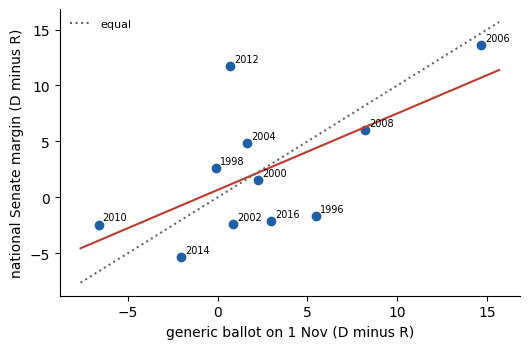

In [13]:
gb = pd.read_csv(DATA / "generic_topline_historical.csv")   # daily generic ballot averages
gb["date"] = pd.to_datetime(gb.modeldate)
gb["gmargin"] = gb.dem_estimate - gb.rep_estimate
# per year: generic ballot on or before 1 Nov; national Senate margin
rows = []
for y in range(1996, 2017, 2):
    sub = gb[gb.date <= f"{y}-11-01"].sort_values("date").iloc[-1]
    r = races[(races.year == y) & races.contested]
    smargin = 100 * (r.dv.sum() - r.rv.sum()) / r.total.sum()
    rows.append(dict(year=y, generic=sub.gmargin, senate_nat=smargin, midterm=(y % 4 == 2)))
ng = pd.DataFrame(rows)
ng["gap"] = ng.senate_nat - ng.generic
show_table(ng.round(1), index=False)
ols = smf.ols("senate_nat ~ generic", ng).fit()   # national Senate margin on the generic ballot
print(f"\nSenate national margin = {ols.params['Intercept']:.2f} + {ols.params['generic']:.2f} x generic ballot; "
      f"R2 = {ols.rsquared:.2f}, residual SD = {np.sqrt(ols.scale):.1f} points")
print(f"Mean of (Senate national margin minus generic ballot): {ng.gap.mean():.1f} points; SD {ng.gap.std():.1f}")
n_pos, n_smaller = int((ng.generic > 0).sum()), int((ng.gap[ng.generic > 0] < 0).sum())
print(f"Years with a generic-ballot lead above 0: {n_pos}; Democrats got a smaller Senate margin than the generic ballot in {n_smaller} of them")

# scatter, fit (red), equality (dotted)
fig, ax = plt.subplots(figsize=(5.4, 3.6))
ax.scatter(ng.generic, ng.senate_nat, color=BLUE)
for r in ng.itertuples():
    ax.annotate(str(r.year), (r.generic, r.senate_nat), fontsize=7, xytext=(3, 3), textcoords="offset points")
xs = np.linspace(ng.generic.min() - 1, ng.generic.max() + 1, 20)
ax.plot(xs, ols.params["Intercept"] + ols.params["generic"] * xs, color=RED)
ax.plot(xs, xs, color=GREY, ls=":", label="equal")
ax.set_xlabel("generic ballot on 1 Nov (D minus R)"); ax.set_ylabel("national Senate margin (D minus R)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

**Reading the result**

- Slope 0.68: 1 point of generic lead ≈ 0.7 points of Senate margin.
- Residual SD 5.1 points (poll error + changing seats).
- Mean difference -0.1 points: no systematic over- or understatement. SD 5.1: single years can be far off.
- 6 of 8 Democratic-lead years: Senate margin below the generic ballot.
- 2026: about D+8.7 (PollCheck, 27 October), D+8.9 (Silver Bulletin, 7 October, search snippet, not verified). Above every sample year except 2006: extrapolation.

### 3b. State lean from the last presidential result

- $\text{lean}_{s}$: margin of state $s$ in the last presidential election before the race (2024 for 2026). National margin subtracted only for display.

- Each contested Senate race against its state's lean, with the fitted line $y_i = a + b\,\text{lean}_i + e_i$; 2024 margins of 2026 battlegrounds.

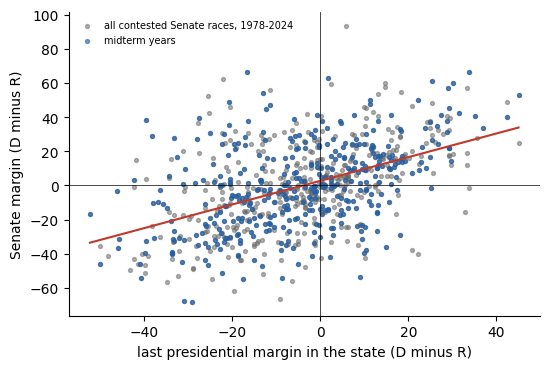

Senate margin on lean alone: slope 0.69, R2 0.23, residual SD 22.1

2024 presidential margin, national: -1.5


,pmargin
state_po,
GA,-2.2
ME,6.8
MI,-1.4
NH,2.8
NC,-3.2
OH,-11.2
IA,-13.2
TX,-13.7
AK,-13.1


In [14]:
fig, ax = plt.subplots(figsize=(5.6, 3.8))
mid = fit[fit.year % 4 == 2]   # midterm-year races, shown in blue
ax.scatter(fit.lean, fit.margin, s=8, color=GREY, alpha=0.5, label="all contested Senate races, 1978-2024")
ax.scatter(mid.lean, mid.margin, s=8, color=BLUE, alpha=0.6, label="midterm years")
lin = smf.ols("margin ~ lean", fit).fit()
xs = np.linspace(fit.lean.min(), fit.lean.max(), 20)
ax.plot(xs, lin.params["Intercept"] + lin.params["lean"] * xs, color=RED)
ax.axhline(0, color="black", lw=0.5); ax.axvline(0, color="black", lw=0.5)
ax.set_xlabel("last presidential margin in the state (D minus R)"); ax.set_ylabel("Senate margin (D minus R)")
ax.legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()
print(f"Senate margin on lean alone: slope {lin.params['lean']:.2f}, R2 {lin.rsquared:.2f}, residual SD {np.sqrt(lin.scale):.1f}")

p24 = pt.pmargin.xs(2024, level="year")   # 2024 presidential margin by state
natl24 = nat.loc[2024]
print(f"\n2024 presidential margin, national: {natl24:.1f}")
show = ["GA", "ME", "MI", "NH", "NC", "OH", "IA", "TX", "AK", "KS"]
show_table((p24[show]).round(1), index=True)

### 3c. A Senate fundamentals regression

**Model.** For each contested race $i$ in year $t$,

$$ y_i = \beta_0 + \beta_1\,\text{lean}_i + \beta_2\,\text{inc}_i + \beta_3\,\text{backlash}_t + \varepsilon_i. $$

- $y_i$: Senate margin (points). $\text{lean}_i$: last presidential margin in the state.
- $\text{inc}_i$: $+1$ Democratic incumbent, $-1$ Republican, $0$ open seat. Incumbent: won a Senate race in the state in the previous six years. Appointees coded as open seats.
- $\text{backlash}_t$: $+1$ midterm with a Republican president, $-1$ with a Democratic president, $0$ presidential year. Known before the election. $\beta_3$ = midterm penalty (points toward the party out of the White House).
- $\varepsilon_i$: shared (year) error + race error.
- Generic ballot would be better, but its file ends in 2016. Fit starts in 1978 (1976 needs the 1972 presidential result, not in the data).

- Fits the regression; splits residual variance into year and race parts; plots year-level misses.
- Residual $u_i = y_i - \hat y_i$. Year $t$ has $n_t$ races, mean residual $\bar u_t$; $N$ races, $T$ years.
- Race variance: $\sigma_w^2 = \sum_t\sum_{i\in t}(u_i - \bar u_t)^2/(N - T)$.
- Shared variance (method of moments): $\sigma_{sh}^2 = \max\bigl(\operatorname{var}_t(\bar u_t) - \overline{\sigma_w^2/n_t},\ 0\bigr)$. Shared fraction: $\rho = \sigma_{sh}^2/(\sigma_{sh}^2 + \sigma_w^2)$.

,estimate,std err
Intercept,1.864,0.64
lean,0.509,0.038
inc,17.647,0.87
backlash,6.959,0.898



Residual SD (all contested races, 789 races): 17.28 points; R2 0.53
Shared (year-level) SD: 4.98; race-level SD: 16.55; share of variance that is shared: 0.08


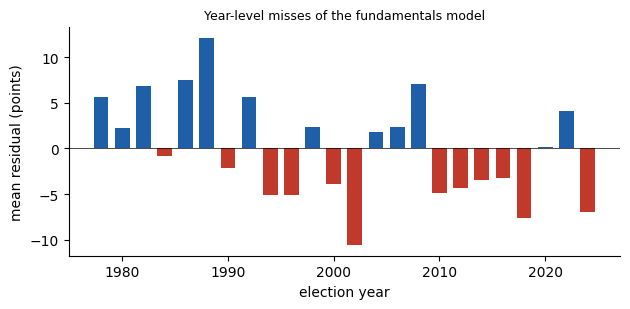

In [15]:
m = smf.ols("margin ~ lean + inc + backlash", fit).fit()   # the fundamentals regression
sd_total = np.sqrt(m.scale)
coef = pd.DataFrame({"estimate": m.params, "std err": m.bse})
show_table(coef.round(3), index=True)
print(f"\nResidual SD (all contested races, {int(m.nobs)} races): {sd_total:.2f} points; R2 {m.rsquared:.2f}")

# Method of moments: year (shared) and race parts of the residual:
# var(year means) minus race-noise contribution.
fit["res"] = m.resid
by = fit.groupby("year").res.agg(["mean", "count", "var"])
within_var = (fit.groupby("year").res.apply(lambda s: ((s - s.mean()) ** 2).sum()).sum()) / (len(fit) - fit.year.nunique())
shared_var = max(by["mean"].var(ddof=1) - (within_var / by["count"]).mean(), 0)
sd_shared, sd_within = np.sqrt(shared_var), np.sqrt(within_var)
rho = shared_var / (shared_var + within_var)
print(f"Shared (year-level) SD: {sd_shared:.2f}; race-level SD: {sd_within:.2f}; share of variance that is shared: {rho:.2f}")

# bar chart of the mean residual in each year
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.bar(by.index, by["mean"], width=1.4, color=[BLUE if v > 0 else RED for v in by["mean"]])
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("election year"); ax.set_ylabel("mean residual (points)")
ax.set_title("Year-level misses of the fundamentals model", fontsize=9)
plt.tight_layout(); plt.show()

**Reading the result**

- Lean 0.51: 10 points more Democratic lean, 5.1 points more Democratic Senate margin.
- Incumbent: 17.6 points toward the incumbent's party, against an open seat.
- Midterm penalty: 7.0 points.
- Residual SD 17.3 (includes uncompetitive and unusual races).
- Shared: about 8% of variance (SD 5.0); race SD 16.5. Shared error moves all races together (Section 5).
- Only 24 election years: shared SD uncertain.

### 3d. Adjusting the environment with the generic ballot

- Check: regress the 3c year-level miss on the generic ballot, 11 years with both.
- $u_t$: mean 3c residual in year $t$. $g_t$: generic ballot on 1 November. Fit $u_t = c_0 + c_1 g_t$.
- 2026: $g = 8.6$, mean of five aggregators on 3 November (RCP, Silver Bulletin, 50+1, DDHQ, NBC), Wikipedia 2026 Senate page, <https://en.wikipedia.org/wiki/2026_United_States_Senate_elections>.
- $\delta = c_0 + 8.6\,c_1$, added to every 2026 fundamentals prediction (Section 7).

In [16]:
GB_2026 = 8.6   # 3 Nov 2026, mean of five aggregators (Wikipedia)
# 3c year mean residuals with the generic ballot
ud = by["mean"].rename("u").reset_index()
ud = ud[ud.year.isin(ng.year)].merge(ng[["year", "generic"]])
gfit = smf.ols("u ~ generic", ud).fit()   # u = c0 + c1 g
DELTA = float(gfit.params["Intercept"] + GB_2026 * gfit.params["generic"])
print(f"Year-level residual on generic ballot ({len(ud)} years): c0 = {gfit.params['Intercept']:.2f} (se {gfit.bse['Intercept']:.2f}), c1 = {gfit.params['generic']:.2f} (se {gfit.bse['generic']:.2f}), R2 = {gfit.rsquared:.2f}")
print(f"Generic ballot range in these years: {ng.generic.min():.1f} to {ng.generic.max():.1f}; 2026 value {GB_2026}")
print(f"Environment adjustment delta for 2026: {DELTA:+.2f} points")

Year-level residual on generic ballot (11 years): c0 = -3.12 (se 1.51), c1 = 0.43 (se 0.26), R2 = 0.24
Generic ballot range in these years: -6.6 to 14.7; 2026 value 8.6
Environment adjustment delta for 2026: +0.61 points


**Reading the result**

- $c_1$ = 0.43, standard error 0.26, 11 years: weak.
- Adjustment for D+8.6: +0.61 points. Small: the midterm penalty already gives 7.0.
- 8.6 exceeds every sample year except 2006 (D+14.7): partly extrapolation.

## 4. Blending polls and fundamentals

- Combine two unbiased estimates with inverse-variance weights (FiftyPlusOne's "stacking by out-of-sample uncertainty"). Output feeds Section 5.

**Notation**

- Fundamentals: mean $\mu_f$, variance $v_f = \sigma_f^2$ ($\sigma_f$: Section 3c residual SD).
- Polls: mean $\mu_p$, variance $v_p$.
- Blend weight (`poll_weight`): $w_p = \dfrac{1/v_p}{1/v_p + 1/v_f}$.
- Blend: $\mu_b = w_p \mu_p + (1 - w_p)\mu_f$, variance $v_b = \dfrac{1}{1/v_p + 1/v_f}$.

**Poll variance**

$$ v_p(d) = \sigma_{sys}^2 + \frac{\sigma_{samp}^2}{k} + \kappa\, d, $$

- $d$: days to the election. $k$: polls averaged.
- $\sigma_{sys}$: systematic error shared by a race's polls. $\sigma_{samp}$: sampling error of one poll average. $\kappa$: variance added per day.
- **$\sigma_{sys} = 4.0$, $\sigma_{samp} = 3.0$, $\kappa = 0.25$ are assumptions, not estimates** (no poll archives; Section 6).

- Poll variance, poll weight, blend; weight against days to the election; one worked example.
- No polls: $w_p = 0$, so $\mu_b = \mu_f$ and $v_b = v_f$. Section 7 passes each race's own number of polls as $k$.

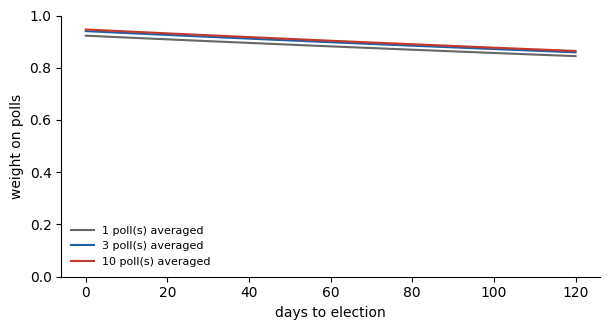

Poll weight with 3 polls: 0.94 on election day, 0.92 at 30 days, 0.88 at 90 days
Fundamentals SD 17.3; poll SD on election day with 3 polls 4.4
Example (made up): fundamentals -4.0, polls +3.0, 3 days out -> blend +2.57, SD 4.30, poll weight 0.94
Poll SD and poll weight 3 days out, by number of polls k: k = 1: 5.1, 0.92; k = 14: 4.2, 0.94; k = 28: 4.1, 0.95


In [17]:
SIG_SYS, SIG_SAMP, KAPPA = 4.0, 3.0, 0.25  # assumptions, see text


def poll_var(days, k=3):
    """Variance of a poll average: systematic + sampling / k + drift x days."""
    return SIG_SYS ** 2 + SIG_SAMP ** 2 / k + KAPPA * np.asarray(days, dtype=float)


def poll_weight(days, k=3, vf=sd_total ** 2):
    """Inverse-variance weight on polls; vf is the fundamentals variance."""
    vp = poll_var(days, k)
    return (1 / vp) / (1 / vp + 1 / vf)


def blend(mu_f, mu_p, days=3, k=3, vf=sd_total ** 2):
    """Inverse-variance blend.  Returns mean, variance and poll weight.  mu_p may be NaN (no polls)."""
    mu_f, mu_p = np.asarray(mu_f, float), np.asarray(mu_p, float)
    w = np.where(np.isnan(mu_p), 0.0, poll_weight(days, k, vf))
    mean = w * np.nan_to_num(mu_p) + (1 - w) * mu_f
    var = np.where(w > 0, 1 / (1 / poll_var(days, k) + 1 / vf), vf)
    return mean, var, w


# plot the poll weight for 1, 3 and 10 polls averaged
days = np.arange(0, 121)
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for k, c in ((1, GREY), (3, BLUE), (10, RED)):
    ax.plot(days, poll_weight(days, k), color=c, label=f"{k} poll(s) averaged")
ax.set_xlabel("days to election"); ax.set_ylabel("weight on polls"); ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
w0, w30, w90 = (float(poll_weight(d, 3)) for d in (0, 30, 90))
print(f"Poll weight with 3 polls: {w0:.2f} on election day, {w30:.2f} at 30 days, {w90:.2f} at 90 days")
print(f"Fundamentals SD {sd_total:.1f}; poll SD on election day with 3 polls {np.sqrt(poll_var(0, 3)):.1f}")

# Example (made up): fundamentals D-4, polls D+3.
ex_mean, ex_var, ex_w = blend(-4.0, 3.0, days=3, k=3)
print(f"Example (made up): fundamentals -4.0, polls +3.0, 3 days out -> blend {float(ex_mean):+.2f}, SD {float(np.sqrt(ex_var)):.2f}, poll weight {float(ex_w):.2f}")

# Section 7 uses each race's own number of polls k, 3 days out
print("Poll SD and poll weight 3 days out, by number of polls k: " +
      "; ".join(f"k = {k}: {np.sqrt(poll_var(3, k)):.1f}, {float(poll_weight(3, k)):.2f}" for k in (1, 14, 28)))

**Reading the plot**

- Three polls: poll weight 0.94 on election day, 0.92 at 30 days, 0.88 at 90 days.
- More polls raise the weight, with diminishing returns: $\sigma_{sys}$ floors the variance. Section 7 uses each race's own $k$: 3 days out, 1 poll gives weight 0.92, 14 polls 0.94, 28 polls 0.95.

**Polls against fundamentals**

- $\sigma_f = 17.3$ ("Fundamentals SD") against poll SD 4.4: polls dominate whenever they exist. No polls: fundamentals alone, wide.
- 50+1's fundamentals lead months out: more predictors (fundraising, experience, personal vote), more precise.
- Poll variance parameters are assumptions; a larger $\kappa$ lowers the weight faster.

### Exercise E.2: blend weight

- Inverse-variance blend (Section 4), variance v = SD².
- Inputs (margins D - R, points): `E2_MU_F` = -3.0, `E2_SD_F` = 12.0 (fundamentals); `E2_MU_P` = 2.0, `E2_SD_P` = 4.5 (polls).
- Formulas: $w_p = (1/v_p) / (1/v_p + 1/v_f)$; blend = $w_p \mu_p + (1 - w_p)\mu_f$.
- Define `w_poll` (share, 0 to 1; 3 decimals) and `blend_margin` (points; 2 decimals). `blend` is the Section 4 function.

In [ ]:
E2_MU_F, E2_SD_F = -3.0, 12.0   # fundamentals margin and SD, points
E2_MU_P, E2_SD_P = 2.0, 4.5      # poll average and SD, points
w_poll = None  # YOUR CODE
blend_margin = None  # YOUR CODE

In [ ]:
check("w_poll", w_poll, "84083b5ae079946e", ndigits=3)
check("blend_margin", blend_margin, "8e9ca257cf0df51d", ndigits=2)

## 5. Simulation and the shared error

- Control needs the joint distribution of races: polling errors and late shifts are national, so races miss together.

**Model.** For race $i$,

$$ M_i = \mu_i + \sqrt{\rho\, v_i}\; z_0 + \sqrt{(1 - \rho)\, v_i}\; z_i, $$

- $\mu_i$, $v_i$: blended mean and variance (Section 4).
- $z_0$: national error, one per draw, shared by all races. $z_i$: race error.
- $\rho$: shared fraction of error variance (Section 3c).
- Each $z = t_\nu\sqrt{(\nu - 2)/\nu}$, $\nu = 10$: Student-t, 10 df, unit SD (50+1 also uses about 10 df).
- Democrat wins race $i$ if $M_i > 0$. Seats in draw $b$: $S_b = 34 + \sum_i \mathbb 1[M_{ib} > 0]$. Control probability: $\frac{1}{B}\sum_b \mathbb 1[S_b \ge 51]$, $B = 40{,}000$ draws (34 seats not up + 17 or more wins of the 35).

- The 35 seats up, holding party, open seats; fundamentals prediction per seat: $\hat\mu_i = \hat\beta_0 + \hat\beta_1\,\text{lean}_i + \hat\beta_2\,\text{inc}_i + \hat\beta_3$ (backlash $= 1$: 2026 midterm, Republican president).
- Here all 35 are contested. Section 7 replaces the open-seat list with the race-table status column and sets P(Democrat wins) = 0 in the three races with no Democrat.

In [20]:
UP = {  # postal code: (name, holding party)
    "AL": ("Alabama", "R"), "AK": ("Alaska", "R"), "AR": ("Arkansas", "R"), "CO": ("Colorado", "D"),
    "DE": ("Delaware", "D"), "FL": ("Florida", "R"), "GA": ("Georgia", "D"), "ID": ("Idaho", "R"),
    "IL": ("Illinois", "D"), "IA": ("Iowa", "R"), "KS": ("Kansas", "R"), "KY": ("Kentucky", "R"),
    "LA": ("Louisiana", "R"), "ME": ("Maine", "R"), "MA": ("Massachusetts", "D"), "MI": ("Michigan", "D"),
    "MN": ("Minnesota", "D"), "MS": ("Mississippi", "R"), "MT": ("Montana", "R"), "NE": ("Nebraska", "R"),
    "NH": ("New Hampshire", "D"), "NJ": ("New Jersey", "D"), "NM": ("New Mexico", "D"), "NC": ("North Carolina", "R"),
    "OH": ("Ohio", "R"), "OK": ("Oklahoma", "R"), "OR": ("Oregon", "D"), "RI": ("Rhode Island", "D"),
    "SC": ("South Carolina", "R"), "SD": ("South Dakota", "R"), "TN": ("Tennessee", "R"), "TX": ("Texas", "R"),
    "VA": ("Virginia", "D"), "WV": ("West Virginia", "R"), "WY": ("Wyoming", "R"),
}
# Open seats: Ballotpedia battleground table; Louisiana: Cassidy lost his
# primary (other source, unverified). Others: incumbent running.
OPEN = {"MI", "MN", "NH", "IA", "MT", "NC", "LA"}
NAME2PO = {v[0]: k for k, v in UP.items()}

# one row per seat
seats = pd.DataFrame([dict(po=po, state=v[0], inc_party=v[1], open=(po in OPEN)) for po, v in UP.items()])
seats["pres24"] = [pm[(2024, po)] for po in seats.po]   # 2024 presidential margin from the MEDSL file
seats["inc"] = np.where(seats.open, 0, np.where(seats.inc_party == "D", 1, -1))   # +1 D incumbent, -1 R incumbent, 0 open
seats["backlash"] = 1  # 2026 is a midterm with a Republican president
seats["fund"] = m.predict(seats.rename(columns={"pres24": "lean"}))
print("Seats up:", len(seats), "| Democratic-held:", int((seats.inc_party == "D").sum()),
      "| Republican-held:", int((seats.inc_party == "R").sum()), "| open:", int(seats.open.sum()))
print("Fundamentals-only predicted margins for a few seats (D minus R, points):")
show_table(seats.set_index("po").fund.round(1)[["GA", "ME", "MI", "NH", "NC", "OH", "IA", "TX", "AK", "KS"]], index=True)

Seats up: 35 | Democratic-held: 13 | Republican-held: 22 | open: 7
Fundamentals-only predicted margins for a few seats (D minus R, points):


,fund
po,
GA,25.4
ME,-5.3
MI,8.1
NH,10.2
NC,7.2
OH,-14.5
IA,2.1
TX,-15.8
AK,-15.5


- Simulation on fundamentals: shared + race errors against independent errors (same race variance). Seat distributions compared.

Fundamentals only, 40,000 draws.  Shared fraction rho = 0.08 versus independent errors (rho = 0).
Each race has the same marginal win probability in both runs: True


,correlated,independent
mean Democratic-caucus seats,50.106,50.091
SD of seats,2.698,1.913
5th percentile,46,47
95th percentile,55,53
P(51 or more seats),0.425,0.408


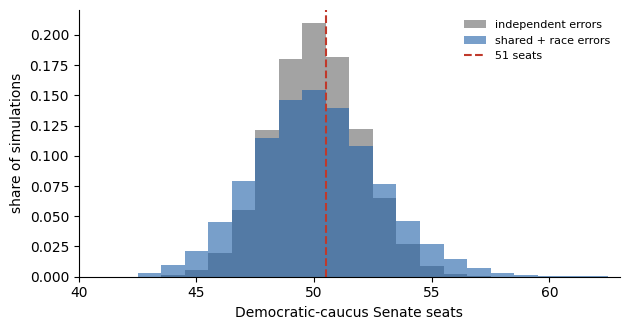

In [21]:
DRAWS = 40000
DF = 10   # degrees of freedom of the Student-t errors


def unit_t(rng, size):
    """Student-t draws with 10 degrees of freedom, rescaled to unit SD."""
    return rng.standard_t(DF, size=size) * np.sqrt((DF - 2) / DF)


def simulate(mu, var, rho, draws=DRAWS, seed=5):
    """Margins for all races: mean + shared national error + race error.  Returns draws x races."""
    rng = np.random.default_rng(seed)
    z0 = unit_t(rng, (draws, 1))
    z = unit_t(rng, (draws, len(mu)))
    sd = np.sqrt(var)
    return mu + np.sqrt(rho) * sd * z0 + np.sqrt(1 - rho) * sd * z


D_SAFE, NEED = FACTS["d_safe"], FACTS["need"]   # 34 caucus seats not up; 51 seats for control
mu_f = seats.fund.values
sim_corr = simulate(mu_f, np.full(len(mu_f), sd_total ** 2), rho)
sim_ind = simulate(mu_f, np.full(len(mu_f), sd_total ** 2), 0.0)
# seats per draw: 34 + races with margin > 0
seats_corr = D_SAFE + (sim_corr > 0).sum(axis=1)
seats_ind = D_SAFE + (sim_ind > 0).sum(axis=1)
print(f"Fundamentals only, {DRAWS:,} draws.  Shared fraction rho = {rho:.2f} versus independent errors (rho = 0).")
print("Each race has the same marginal win probability in both runs:",
      np.allclose((sim_corr > 0).mean(0), (sim_ind > 0).mean(0), atol=0.01))
tab = pd.DataFrame({
    "correlated": [seats_corr.mean(), seats_corr.std(), np.percentile(seats_corr, 5), np.percentile(seats_corr, 95), (seats_corr >= NEED).mean()],
    "independent": [seats_ind.mean(), seats_ind.std(), np.percentile(seats_ind, 5), np.percentile(seats_ind, 95), (seats_ind >= NEED).mean()],
}, index=["mean Democratic-caucus seats", "SD of seats", "5th percentile", "95th percentile", "P(51 or more seats)"])
show_table(tab.round(3), index=True)

# seat histograms, both error models
fig, ax = plt.subplots(figsize=(6.4, 3.4))
bins = np.arange(seats_ind.min() - 0.5, seats_corr.max() + 1.5)
ax.hist(seats_ind, bins=bins, density=True, alpha=0.6, color=GREY, label="independent errors")
ax.hist(seats_corr, bins=bins, density=True, alpha=0.6, color=BLUE, label="shared + race errors")
ax.axvline(NEED - 0.5, color=RED, ls="--", label="51 seats")
ax.set_xlim(40, 63)
ax.set_xlabel("Democratic-caucus Senate seats"); ax.set_ylabel("share of simulations")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

**Reading the result**

- Seat SD: 1.91 independent, 2.70 shared (competitive races move together).
- 5th to 95th percentile: 46 to 55 shared, 47 to 53 independent.
- P(51 or more): 0.425 shared, 0.408 independent. Close because control is near a coin flip; with a clear favorite the independent model is overconfident (Section 7).
- Shared fraction only 0.08: a mild case. Hence the platforms' national, regional and state errors.

### Exercise E.3: win and control probability

- Task 1: P(Democrat wins), one race. Margin `E3_MARGIN` = 3.0, error SD `E3_SD` = 10.0 (points). Student-t error with `DF` df, scaled to that SD (as `unit_t`).
- Formula: $P(D) = F_\nu\!\bigl(m / (s\sqrt{(\nu - 2)/\nu})\bigr)$, $F_\nu$ the Student-t cdf (`stats.t.cdf`; `tcdf_prob` in Section 6).
- Task 2: control probability = share of draws with `D_SAFE` + wins >= `NEED`, from `simulate(mu, var, rho_x)` with its default draws and seed. Race mean `mu_f + E3_SHIFT` (`E3_SHIFT` = 5.0), race variance `sd_total ** 2`.
- Base: `rho_x = rho`. Wide: shared SD = backtest year-level SD `E3_YEAR_SD` = 6.45, so `rho_x = E3_YEAR_SD ** 2 / sd_total ** 2`.
- Define `p_win`, `p_control_base`, `p_control_wide` (probabilities; 3 decimals).
- A wider shared error lowers the favorite's control probability (Section 7 overconfidence).

In [ ]:
E3_MARGIN, E3_SD = 3.0, 10.0       # one race: margin and error SD, points
E3_SHIFT, E3_YEAR_SD = 5.0, 6.45   # national shift; Section 6 year-level SD, points
p_win = None  # YOUR CODE
p_control_base = None  # YOUR CODE
p_control_wide = None  # YOUR CODE

In [ ]:
check("p_win", p_win, "c22904d375742ac8", ndigits=3)
check("p_control_base", p_control_base, "ac156581f624ede6", ndigits=3)
check("p_control_wide", p_control_wide, "aa2105b816cbae43", ndigits=3)

## 5b. Calibration

- A number in [0, 1] is a probability once it passes a check against outcomes (Sections 6, 7, 10). [Calibration Lab](https://vsokolov.org/labs/calibration-lab.html).

**Terms**

- Event: yes/no question. Forecast $p_i$; outcome $y_i = 1$ if it happened, else 0.
- Base rate $\bar y$: share of events that happened.
- Calibration: of events given $p$, a fraction $p$ happen.
- Bin: forecasts with nearby values (e.g., 0.6 to 0.7). Calibration is checked per bin.
- Reliability diagram: bin event share against bin mean forecast; calibrated = diagonal.
- Discrimination: higher forecasts for events that happen.
- Sharpness: distance of forecasts from the base rate, toward 0 or 1.
- Calibration and discrimination are independent.

**Why it matters**

- Decisions use $p$: Kelly stake (Lab 8), expected cost = cost × $p$. Wrong $p$, wrong stake.
- Probabilities combine (averages, expected seats); rankings do not.
- In-sample scores overstate quality (Lab 11): 745 coefficients on 1,000 loans look calibrated in sample only (Calibration Lab). Section 6 holds out whole years.

**Scores.** $n$ forecasts, $G$ bins; bin $g$ has $n_g$ forecasts, mean forecast $\bar p_g$, event share $\bar y_g$.

- **Accuracy**: $\frac{1}{n}\sum_i \mathbb 1\bigl[\mathbb 1(p_i > 0.5) = y_i\bigr]$, share right with \"yes if $p_i > 0.5$\"; ignores confidence.
- **AUC**: $\frac{1}{n_1 n_0}\sum_{i:y_i=1}\sum_{k:y_k=0}\bigl[\mathbb 1(p_i > p_k) + \tfrac12\mathbb 1(p_i = p_k)\bigr]$ ($n_1$ events, $n_0$ non-events): P(random event that happened outranks random one that did not); ties 1/2. 0.5 no ranking, 1 perfect. Blind to miscalibration.
- **ECE** (expected calibration error):

$$\text{ECE} = \sum_{g=1}^{G} \frac{n_g}{n}\,\bigl|\bar p_g - \bar y_g\bigr|$$

  0 = calibrated. Noisy in small bins. Always saying the base rate gives ECE 0.

- **Brier score**:

$$\text{Brier} = \frac{1}{n}\sum_{i=1}^{n} (p_i - y_i)^2$$

  0 perfect, 0.25 always 50%.
  Why Brier:
  - Proper: reporting your true $p$ minimizes it, so no gain from shading.
  - Scores the probability, not just the winner.
  - Bounded (at most 1): one surprise cannot dominate, unlike log loss.
  - Splits into calibration and resolution (below).

- **Log loss**:

$$\text{log loss} = -\frac{1}{n}\sum_{i=1}^{n}\bigl[y_i \log p_i + (1-y_i)\log(1-p_i)\bigr]$$

  Proper. Code clips $p_i$ to [0.001, 0.999]. 1% on an event that happens: 4.6 (Brier 0.98). Always 50%: 0.693.

- **Murphy decomposition** (Murphy, 1973):

$$\text{Brier} = \text{REL} - \text{RES} + \text{UNC}$$

$$\text{REL} = \sum_{g=1}^{G} \frac{n_g}{n}\,(\bar p_g - \bar y_g)^2, \qquad \text{RES} = \sum_{g=1}^{G} \frac{n_g}{n}\,(\bar y_g - \bar y)^2, \qquad \text{UNC} = \bar y\,(1-\bar y)$$

  - REL: cost of bad numbers; lower better.
  - RES: value of information; higher better.
  - UNC: Brier of always saying the base rate; same for every forecaster.
  - Exact only when forecasts within a bin are equal.

| Property | Measures |
|---|---|
| Calibration: numbers mean what they say | ECE, REL |
| Discrimination: separates events that happen from those that do not | AUC, accuracy, RES |
| Both | Brier score, log loss |

**Three cases**

- Calibrated but useless: always the base rate. REL = 0, RES = 0.
- Sharp but miscalibrated: ranks well, too extreme. High AUC, large REL.
- Both: the aim, maximum sharpness subject to calibration (Gneiting, Balabdaoui and Raftery, 2007).
- Recalibrating (new numbers, same order) lowers REL, leaves AUC unchanged.

- Code: `calib_table`, `auc`, `murphy`; one simulated forecaster per case, 20,000 simulated events.

In [24]:
# Probability scores, Murphy decomposition, bins of width 0.1
def calib_table(p, y, width=0.1):
    """Group forecasts p into bins of the given width; return the count, mean forecast and share of events per bin."""
    p, y = np.asarray(p, float), np.asarray(y, float)
    k = np.minimum((p / width).astype(int), int(round(1 / width)) - 1)   # bin index; p = 1 goes in the last bin
    return pd.DataFrame({"k": k, "p": p, "y": y}).groupby("k").agg(n=("y", "size"), p_bar=("p", "mean"), y_bar=("y", "mean"))


def auc(p, y):
    """P(forecast of a random event that happened > forecast of a random event that did not); ties count 1/2."""
    p, y = np.asarray(p, float), np.asarray(y, int)
    r = stats.rankdata(p)
    n1, n0 = y.sum(), (1 - y).sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def murphy(p, y, width=0.1):
    """Accuracy, AUC, ECE, Brier score, log loss and the decomposition Brier = REL - RES + UNC (exact only if each bin holds one forecast value)."""
    p, y = np.asarray(p, float), np.asarray(y, float)
    d = calib_table(p, y, width)
    w, yb = d.n / d.n.sum(), y.mean()          # share of forecasts per bin; overall share of events
    pc = np.clip(p, 1e-3, 1 - 1e-3)
    return dict(accuracy=np.mean((p > .5) == (y == 1)), AUC=auc(p, y), ECE=(w * (d.p_bar - d.y_bar).abs()).sum(),
                REL=(w * (d.p_bar - d.y_bar) ** 2).sum(), RES=(w * (d.y_bar - yb) ** 2).sum(), UNC=yb * (1 - yb),
                Brier=np.mean((p - y) ** 2), log_loss=-np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc)))


# SIMULATED events: q true chance, y outcome; three forecasters
rng_c = np.random.default_rng(5)
n_sim = 20000
q_true = rng_c.uniform(0.001, 0.999, n_sim)
y_sim = (rng_c.uniform(size=n_sim) < q_true).astype(int)
cases = {"Always the base rate": np.full(n_sim, y_sim.mean()),
         "Sharp but overconfident": 1 / (1 + np.exp(-3 * np.log(q_true / (1 - q_true)))),   # logit stretched by 3
         "Sharp and calibrated": q_true}
three = pd.DataFrame({k: murphy(v, y_sim) for k, v in cases.items()}).T
print(f"{n_sim} simulated events, {y_sim.mean():.3f} of them happened")
show_table(three.round(3), index=True)


20000 simulated events, 0.505 of them happened


,accuracy,AUC,ECE,REL,RES,UNC,Brier,log_loss
Always the base rate,0.505,0.5,0,0,0,0.25,0.25,0.693
Sharp but overconfident,0.748,0.834,0.144,0.022,0.078,0.25,0.192,0.697
Sharp and calibrated,0.748,0.834,0.009,0,0.083,0.25,0.166,0.5


**Reading the table**

- Base rate: ECE, REL, RES 0.000; AUC 0.500; Brier 0.250 = UNC. Calibrated, useless.
- Calibrated and overconfident (same order): AUC 0.834, accuracy 0.748 for both.
- Overconfident against calibrated: ECE 0.144 against 0.009, REL 0.022 against 0.000, Brier 0.192 against 0.166.
- Log loss 0.697 against 0.500: overconfident is worse than the base-rate forecaster (0.693); confident misses are expensive.
- RES 0.078 and 0.083; UNC 0.25 for all three.
- AUC and accuracy cannot separate them; ECE, REL and log loss can.

**Small samples**

- A few forecasts cannot test calibration.
- Binomial interval: 95% range of the event count (or share) for $n$ independent events of probability $p$: $\bigl[F^{-1}_{\mathrm{Bin}(n,p)}(0.025)/n,\ F^{-1}_{\mathrm{Bin}(n,p)}(0.975)/n\bigr]$.
- Code: the interval for $p = 0.60$ and several $n$. Section 7: 33 called races, 1 to 14 per bin. Senate control: one event.

In [25]:
# Central 95% range of the event share, n calibrated forecasts of 0.60:
P_BIN = 0.60
small = [("Senate control (one event)", 1), ("a Section 7 bin", 4), ("the 33 called races of Section 7", 33),
         ("a Section 6 bin", 124), ("all 789 backtest races", 789)]
rng_tab = pd.DataFrame(
    [(lab, n, *(stats.binom.ppf([.025, .975], n, P_BIN) / n)) for lab, n in small],
    columns=["where", "forecasts n", "lowest share", "highest share"]).set_index("where")
print(f"If every forecast is {P_BIN:.2f} and the forecaster is calibrated, 95% of the time the share that happens falls in this range:")
show_table(rng_tab.round(3), index=True)


If every forecast is 0.60 and the forecaster is calibrated, 95% of the time the share that happens falls in this range:


,forecasts n,lowest share,highest share
where,,,
Senate control (one event),1,0,1
a Section 7 bin,4,0,1
the 33 called races of Section 7,33,0.424,0.758
a Section 6 bin,124,0.516,0.685
all 789 backtest races,789,0.565,0.634


**Reading the table**

- 1 event: share 0 or 1; any forecast strictly between 0 and 1 fits. One control result cannot test calibration.
- 4 (a small Section 7 bin; bins hold 1 to 14 races): 0.000 to 1.000; bins this small cannot reject calibration.
- 33 (Section 7 called races): 0.424 to 0.758, about 14 to 25 of 33 events.
- 124 (a Section 6 bin): 0.516 to 0.685.
- 789 (all backtest races): 0.565 to 0.634.
- Calibration is judged on the Section 6 backtest; Section 7 only reports scores.

**Prediction markets**

- A price calibration plot shows calibration, not accuracy (base-rate pricing is calibrated and useless).
- Accuracy is in resolution. Calibrated: Brier = UNC - RES.
- Timing: near the close prices approach 0 or 1; pooling all times rewards late learning.
- Profit needs a forecast better than the price.
- Accuracy claim: proper score at a stated time before close against a benchmark (Calibration Lab, after Harry Crane).
- Section 10: 7,601 Polymarket markets.

**Sources**

- Murphy, A. H. (1973), "A new vector partition of the probability score", Journal of Applied Meteorology 12, 595-600.
- Gneiting, T., Balabdaoui, F. and Raftery, A. E. (2007), "Probabilistic forecasts, calibration and sharpness", Journal of the Royal Statistical Society B 69, 243-268.
- [Calibration Lab](https://vsokolov.org/labs/calibration-lab.html): scores, three cases, prediction-market exercise, hidden die.

## 6. Backtest on history

- Out-of-sample test of the Section 3 fundamentals model on 1978 to 2024 Senate returns, with Section 5b scores.

**Method: leave one year out**

- Fit Section 3c on the other years; predict every contested race in the held-out year.
- Win probability: Student-t error (10 df), SD = training residual SD $s$: $P(D)_i = F_\nu\bigl(\hat m_i/(s\sqrt{(\nu - 2)/\nu})\bigr)$, $\hat m_i$ the out-of-sample prediction.

**Estimates**: error size, shared part, calibration, 80% interval coverage (fundamentals only).

**Not estimable**: poll error (FiveThirtyEight raw polls file gone, no replacement), so $\sigma_{sys}$, $\sigma_{samp}$, $\kappa$ stay assumptions.

- Backtest: out-of-sample errors, interval coverage, Brier scores, calibration table.
- Error $e_i = y_i - \hat m_i$ (actual minus predicted). RMSE $= \sqrt{\frac{1}{N}\sum_i e_i^2}$.
- 80% interval covers race $i$ if $|e_i| < t_{0.9,\nu}\sqrt{(\nu - 2)/\nu}\;s$.
- Year-level error: $\bar e_t$ = mean of $e_i$ in year $t$; its SD over years.

In [26]:
def tcdf_prob(pred, sd):
    """P(Democratic win) when the margin is pred + a Student-t error of SD sd."""
    return stats.t.cdf(pred / (sd * np.sqrt((DF - 2) / DF)), DF)


# for each year: fit on all other years, predict the held-out year
rows = []
for y in sorted(fit.year.unique()):
    tr, te = fit[fit.year != y], fit[fit.year == y]
    mm = smf.ols("margin ~ lean + inc + backlash", tr).fit()
    te = te.assign(pred=mm.predict(te), sd=np.sqrt(mm.scale))   # prediction and training residual SD
    rows.append(te)
cv = pd.concat(rows)
cv["err"] = cv.margin - cv.pred   # actual - predicted
cv["p"] = tcdf_prob(cv.pred, cv.sd)
cv["win"] = (cv.margin > 0).astype(int)
brier = lambda d: np.mean((d.p - d.win) ** 2)
comp = cv[cv.pred.abs() < 10]   # competitive races: predicted within 10 points
t80 = stats.t.ppf(0.9, DF) * np.sqrt((DF - 2) / DF)
print(f"Out-of-sample, {len(cv)} races in {cv.year.nunique()} years")
print(f"RMSE of the margin: {np.sqrt(np.mean(cv.err ** 2)):.2f} points (in-sample residual SD {sd_total:.2f})")
print(f"Share of races inside the 80% interval: {np.mean(cv.err.abs() < t80 * cv.sd):.3f}")
print(f"Brier score, all races: {brier(cv):.3f}; races with |prediction| < 10: {brier(comp):.3f} ({len(comp)} races)")
print(f"Share of races where the favorite won: all {np.mean((cv.p > .5) == (cv.win == 1)):.3f}; |prediction| < 10: {np.mean((comp.p > .5) == (comp.win == 1)):.3f}")
ym = cv.groupby("year").err.mean()
print(f"SD of the year-mean error: {ym.std():.2f} points; largest: {ym.abs().idxmax()} ({ym[ym.abs().idxmax()]:+.1f})")

# calibration by probability bin
cv["bin"] = pd.cut(cv.p, [0, .1, .3, .5, .7, .9, 1.0], include_lowest=True)
cal = cv.groupby("bin", observed=True).agg(races=("win", "size"), mean_p=("p", "mean"), share_won=("win", "mean"))
print("\nCalibration of fundamentals-only probabilities (leave one year out):")
show_table(cal.round(3), index=True)

Out-of-sample, 789 races in 24 years
RMSE of the margin: 17.55 points (in-sample residual SD 17.28)
Share of races inside the 80% interval: 0.809
Brier score, all races: 0.136; races with |prediction| < 10: 0.227 (290 races)
Share of races where the favorite won: all 0.805; |prediction| < 10: 0.634
SD of the year-mean error: 6.45 points; largest: 1988 (+13.6)

Calibration of fundamentals-only probabilities (leave one year out):


,races,mean_p,share_won
bin,,,
"(-0.001, 0.1]",116,0.053,0.069
"(0.1, 0.3]",161,0.186,0.174
"(0.3, 0.5]",125,0.403,0.344
"(0.5, 0.7]",124,0.596,0.581
"(0.7, 0.9]",149,0.812,0.859
"(0.9, 1.0]",114,0.944,0.982


**Reading the result**

- Out-of-sample RMSE 17.55 against in-sample 17.28: not badly overfit.
- 80% interval covers 0.81.
- Brier 0.136 (all races), 0.227 (290 races predicted within 10 points). Always 50%: 0.25.
- FiftyPlusOne: Senate Brier 0.049, 2012 to 2024, with polls (Section 1, source 2). Not like-for-like: ours is fundamentals only.

**Shared error**

- Year-level error SD 6.45 points, above the Section 5 shared SD of 5.0 (in-sample, corrected for races per year).
- Section 5 shared error: a lower estimate; Section 7 control probability probably too confident.

**Reliability diagram and Murphy decomposition of the backtest**

- Bins `cv` (width 0.1): count, mean forecast, Democratic win share per bin. Checks Brier = REL - RES + UNC.
- Bars: 95% Jeffreys intervals per bin, $\bigl[\mathrm{Beta}^{-1}_{0.025}(k+\tfrac12,\,n-k+\tfrac12),\ \mathrm{Beta}^{-1}_{0.975}(k+\tfrac12,\,n-k+\tfrac12)\bigr]$ ($k$ Democratic wins in $n$ races). Histogram below: races per bin.
- Brier skill: $1 - \text{Brier}/\text{UNC}$.

,n,p_bar,y_bar
k,,,
0,116,0.053,0.069
1,98,0.149,0.102
2,63,0.245,0.286
3,66,0.353,0.303
4,59,0.459,0.39
5,66,0.545,0.515
6,58,0.653,0.655
7,61,0.746,0.82
8,88,0.858,0.886


Outside: mean forecast 0.944, share won 0.982 in 114 races, 95% interval [0.945, 0.996]
Bins whose 95% interval contains the mean forecast: 9 of 10
accuracy 0.805  AUC 0.887  ECE 0.038  REL 0.002  RES 0.115  UNC 0.250  Brier 0.136  log_loss 0.425
REL - RES + UNC = 0.1370; Brier score = 0.1362; difference 0.0009 (spread of forecasts inside bins)
Brier skill against always predicting the base rate: 0.455


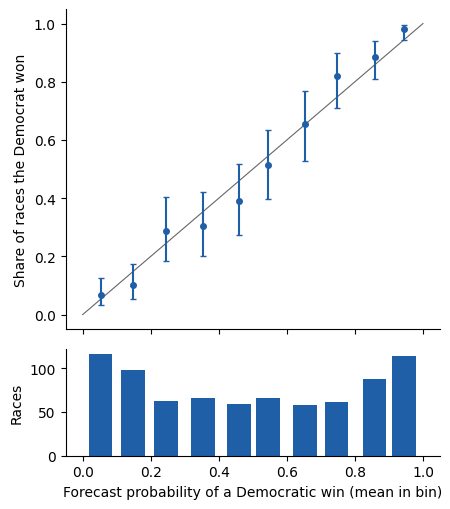

In [27]:
# Reliability diagram and Murphy decomposition of cv
tb = calib_table(cv.p, cv.win)                       # bins of width 0.1
m6 = murphy(cv.p, cv.win)
k_ev = np.round(tb.y_bar * tb.n)                     # events per bin
ci6 = np.array([stats.beta.ppf([.025, .975], k + .5, n - k + .5) for k, n in zip(k_ev, tb.n)])   # Jeffreys 95% intervals
inside = int(((ci6[:, 0] <= tb.p_bar) & (tb.p_bar <= ci6[:, 1])).sum())
show_table(tb.round(3), index=True)
for p_, y_, n_, lo_, hi_ in zip(tb.p_bar, tb.y_bar, tb.n, ci6[:, 0], ci6[:, 1]):
    if not lo_ <= p_ <= hi_:
        print(f"Outside: mean forecast {p_:.3f}, share won {y_:.3f} in {n_} races, 95% interval [{lo_:.3f}, {hi_:.3f}]")
print(f"Bins whose 95% interval contains the mean forecast: {inside} of {len(tb)}")
print("  ".join(f"{k} {v:.3f}" for k, v in m6.items()))
print(f"REL - RES + UNC = {m6['REL'] - m6['RES'] + m6['UNC']:.4f}; Brier score = {m6['Brier']:.4f}; difference {m6['REL'] - m6['RES'] + m6['UNC'] - m6['Brier']:.4f} (spread of forecasts inside bins)")
print(f"Brier skill against always predicting the base rate: {1 - m6['Brier'] / m6['UNC']:.3f}")

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(4.6, 5.2), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax.plot([0, 1], [0, 1], c=GREY, lw=.8)
ax.errorbar(tb.p_bar, tb.y_bar, yerr=[tb.y_bar - ci6[:, 0], ci6[:, 1] - tb.y_bar], fmt="o", c=BLUE, ms=4, capsize=2)
ax.set_ylabel("Share of races the Democrat won")
ax2.bar(tb.p_bar, tb.n, width=.07, color=BLUE)
ax2.set_xlabel("Forecast probability of a Democratic win (mean in bin)"); ax2.set_ylabel("Races")
plt.tight_layout(); plt.show()


**Reading the diagram**

- 58 to 116 races per bin.
- Points near the diagonal; 9 of 10 bin intervals contain the mean forecast.
- Exception, top bin: forecast 0.944, won 0.982, interval [0.945, 0.996]. Safest races won slightly more often than forecast.
- ECE 0.038 (about four points per bin). REL 0.002: miscalibration nearly free.
- RES 0.115, UNC 0.25: 0.25 - 0.115 + 0.002 = 0.137 against exact Brier 0.136 (gap 0.0009: forecasts within a bin differ).
- Brier skill 0.455: 46% below always predicting the base rate.
- AUC 0.887, accuracy 0.805: good separation.
- Fundamentals alone: calibrated and useful out of sample. Not a test of the Section 7 blend (33 races).

## 7. Backcast of 3 November

- Sections 3 to 5 on 2026 races, pre-election information only; scored against Section 0.

**Inputs** (assembled by hand after the election, mainly from the Wikipedia 2026 Senate page)

- `elections_backcast.csv`: per race: incumbent, candidates, call (D or R), 2024 presidential margin, mean final poll margin and number of polls (24 races), rating labels from Silver Bulletin, FiftyPlusOne, DDHQ, RCP and Cook. Vote margins blank (unpublished).
- `elections_polls_final.csv`: the 205 polls behind those means (27 races; Section 2 shows Maine).
- `elections_platforms.csv`: platform control probabilities, seats, generic ballot, date, source.

**Model per race**

- Fundamentals: $\mu_{f,i} = \hat\beta_0 + \hat\beta_1\,\text{lean}_i + \hat\beta_2\,\text{inc}_i + \hat\beta_3 + \delta$ (Section 3c, adjustment $\delta$ of Section 3d).
- 24 polled races: Section 4 blend, 3 days out, $k_i$ = the race's own number of polls; poll input $\mu_p$ = simple mean of its final polls (ended 13 October to 2 November). Polls are 1 to 21 days old and are not age-weighted.
- Other 11 (8 with no polls, 3 with an independent instead of a Democrat): fundamentals only, $w_p = 0$.
- Montana: the margin is Democrat (Bankhead) minus Republican, far behind; the race was Democrat vs independent (Bodnar) vs Republican.
- Then the Section 5 simulation with the shared error: $P(D)_i = \frac{1}{B}\sum_b \mathbb 1[M_{ib} > 0]$, seats $S_b = 34 + \sum_i \mathbb 1[M_{ib} > 0]$, control $\frac{1}{B}\sum_b \mathbb 1[S_b \ge 51]$.

**Incumbency**

- Only senators who won a Senate election count. Appointees coded open, as in the fit: Florida, Ohio, Oklahoma, South Carolina.
  - Oklahoma: appointee ineligible to run.
  - South Carolina: nominee Darline Graham (R), Lindsey Graham's sister, appointed after his death in July 2026 (Wikipedia).
- Retiring incumbents and those who lost renomination: open.

**No Democrat on the ballot**

- Idaho, Nebraska, South Dakota: Democratic nominees withdrew, independents ran; `dem_candidate` blank.
- P(Democrat wins) = 0, applied before counting seats and control.

**Gaps**: Alaska and Mississippi uncalled, left out of every score.

- Forecast for all 35 races.

In [28]:
# match races to seats by state (specials: "(special)")
bc["po"] = bc.state.str.replace(" (special)", "", regex=False).map(NAME2PO)
b2 = bc.set_index("po")
rc = seats.set_index("po").copy()
# rating labels from five forecasters (Wikipedia Predictions table)
RATING_COLS = ["silver_rating", "fpo_rating", "ddhq_rating", "rcp_rating", "cook_rating"]
# needed columns; missing become NaN
for col in ["poll_margin_final", "n_polls", "result_margin", "called", "silver_pD", "fiftyplusone_pD", "ddhq_pD"] + RATING_COLS:
    rc[col] = b2[col] if col in b2 else np.nan
if "pres2024_margin" in b2:
    rc["pres24"] = b2.pres2024_margin.combine_first(rc.pres24)
if "incumbent_party" in b2:
    rc["inc_party"] = b2.incumbent_party.combine_first(rc.inc_party)
# "Incumbent retiring", "Interim appointee": no elected incumbent
if "status" in b2:
    st = b2.status.fillna("").str.lower()
    rc["open"] = st.str.contains("retiring|renomination|ineligible|appointee")
rc["inc"] = np.where(rc.open, 0, np.where(rc.inc_party == "D", 1, -1))
# fundamentals prediction (Section 3c) plus the generic-ballot adjustment (Section 3d)
rc["fund"] = m.predict(rc.reset_index().rename(columns={"pres24": "lean"})).values + DELTA
rc["n_polls"] = rc.n_polls.fillna(1).clip(lower=1)   # races without polls: k unused (poll weight 0)
# blend with poll margin (none: poll weight 0), k = the race's own number of polls
bm, bv, bw = blend(rc.fund.values, rc.poll_margin_final.astype(float).values, days=3, k=rc.n_polls.values)
rc["blend"], rc["sd"], rc["poll_w"] = bm, np.sqrt(bv), bw
sim = simulate(rc.blend.values, bv, rho)   # 40,000 draws with the shared error
# No Democrat on the ballot: margin below zero in every draw,
# so P(win) = 0 and no seat.
rc["no_dem"] = b2.dem_candidate.reindex(rc.index).isna().values
sim[:, rc.no_dem.values] = -100.0
rc["pD"] = (sim > 0).mean(axis=0)
rc["called"] = rc.called.where(rc.called.isin(["D", "R"]))
print(f"Open or appointee-held seats (coded without an incumbent): {int(rc.open.sum())} of {len(rc)}; seats with a poll margin: {int(rc.poll_margin_final.notna().sum())}")
print(f"Polls used: {int(rc.n_polls[rc.poll_margin_final.notna()].sum())} in {int(rc.poll_margin_final.notna().sum())} races (3 polled races have no Democrat and no poll margin)")
print(f"Environment adjustment applied: {DELTA:+.2f}")
print(f"No Democrat on the ballot (win probability set to 0): {', '.join(rc[rc.no_dem].state)}\n")
print("Our forecast for each race (margin D minus R in points; pD = probability of a Democratic win; call = result so far):")
show = rc[["state", "inc_party", "pres24", "poll_margin_final", "fund", "blend", "poll_w", "pD", "called"]].sort_values("pD", ascending=False)
show_table(show.round(2), index=True)

Open or appointee-held seats (coded without an incumbent): 16 of 35; seats with a poll margin: 24
Polls used: 189 in 24 races (3 polled races have no Democrat and no poll margin)
Environment adjustment applied: +0.61
No Democrat on the ballot (win probability set to 0): Idaho, Nebraska, South Dakota

Our forecast for each race (margin D minus R in points; pD = probability of a Democratic win; call = result so far):


,state,inc_party,pres24,poll_margin_final,fund,blend,poll_w,pD,called
po,,,,,,,,,
RI,Rhode Island,D,13.78,31,34.09,31.25,0.92,1,D
MA,Massachusetts,D,25.2,26,39.9,26.86,0.94,1,D
CO,Colorado,D,10.99,20.33,32.67,21.1,0.94,1,D
NM,New Mexico,D,6,19,30.13,19.88,0.92,1,D
IL,Illinois,D,10.9,13.67,14.97,13.75,0.94,1,D
NC,North Carolina,R,-3.21,10.88,7.79,10.71,0.94,0.99,D
GA,Georgia,D,-2.19,9.17,25.96,10.14,0.94,0.99,D
OR,Oregon,D,14.3,,34.35,34.35,0,0.98,D
DE,Delaware,D,14.7,,34.55,34.55,0,0.97,D


- Scores called races and ratings; checks polled races.
- $y_i = 1$ if the Democrat won. Brier $= \frac{1}{n}\sum_i (p_i - y_i)^2$; log loss $= -\frac{1}{n}\sum_i [y_i\log p_i + (1 - y_i)\log(1 - p_i)]$; $p_i$ clipped to [0.001, 0.999].
- Probability given to the actual winner: $y_i p_i + (1 - y_i)(1 - p_i)$.
- Rating to $p$: Solid or Safe 0.97, Likely 0.85, Lean 0.70, Toss-up 0.50; Republican label $1 - p$.
- Fundamentals alone, polled races: $P(D)_i = F_\nu\bigl(\mu_{f,i}/(s\sqrt{(\nu - 2)/\nu})\bigr)$, $s$ = Section 3c residual SD.

In [29]:
# keep the races with a call; y = 1 if the Democrat won
sc = rc[rc.called.notna()].copy()
sc["y"] = (sc.called == "D").astype(int)


def scores(p, y, eps=1e-3):
    """Brier score and log loss.  Probabilities are clipped to [0.001, 0.999] so that log loss stays finite."""
    p = np.clip(np.asarray(p, float), eps, 1 - eps)
    y = np.asarray(y, float)
    return np.mean((p - y) ** 2), -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


b_all, l_all = scores(sc.pD, sc.y)   # our model's scores on the called races
n_fav = int(((sc.pD > .5) == (sc.y == 1)).sum())
print(f"Called races scored: {len(sc)} (D {int(sc.y.sum())}, R {int((1 - sc.y).sum())}). Uncalled, excluded: {', '.join(rc[rc.called.isna()].state)}")
print(f"Our model: Brier {b_all:.3f}, log loss {l_all:.3f}  (always 50%: Brier 0.250, log loss {np.log(2):.3f}); favorite won in {n_fav} of {len(sc)}")
miss = sc[(sc.pD > .5) != (sc.y == 1)].sort_values("pD")
print("Races where the favorite lost (model P(D), call):")
show_table(miss[["state", "inc_party", "pD", "called"]].round(2), index=True)

# probability given to the actual winner
sc["p_winner"] = np.where(sc.y == 1, sc.pD, 1 - sc.pD)
worst = sc.sort_values("p_winner").head(3)
print("Three outcomes the model found least likely (probability the model gave to the actual winner):")
show_table(worst[["state", "called", "p_winner"]].round(2), index=True)
worst_txt = ", ".join(f"{r.state} ({r.p_winner:.2f})" for r in worst.itertuples())

sc["bin"] = pd.cut(sc.pD, [0, .1, .3, .5, .7, .9, 1.0], include_lowest=True)
cal7 = sc.groupby("bin", observed=True).agg(races=("y", "size"), mean_pD=("pD", "mean"), share_D_won=("y", "mean"))
print("\nCalibration of our model on called races (small counts per bin):")
show_table(cal7.round(2), index=True)

# Ratings as forecasts: OUR label-to-probability mapping.
LEVEL = {"solid": 0.97, "safe": 0.97, "likely": 0.85, "lean": 0.70}


def rating_pD(label):
    if pd.isna(label):
        return np.nan
    t = label.lower().replace("(flip)", "").strip()
    if t.startswith("toss"):
        return 0.5
    level, party = t.split()
    return LEVEL[level] if party == "d" else 1 - LEVEL[level]


names = {"silver_rating": "Silver Bulletin rating", "fpo_rating": "FiftyPlusOne rating", "ddhq_rating": "DDHQ rating",
         "rcp_rating": "RCP rating", "cook_rating": "Cook rating"}
# label to P(Democrat wins)
for col in RATING_COLS:
    sc[col + "_p"] = sc[col].map(rating_pD)
sc["ratings_mean_p"] = sc[[c + "_p" for c in RATING_COLS]].mean(axis=1)
# ratings and our model on the same rated races
rows = []
for col, lab in list(names.items()) + [("ratings_mean", "Mean of the five ratings")]:
    pc = col + "_p"
    s2 = sc[sc[pc].notna()]
    if len(s2):
        b2_, l2_ = scores(s2[pc], s2.y)
        b3_, l3_ = scores(s2.pD, s2.y)
        rows.append(dict(forecaster=lab, races=len(s2), brier=b2_, log_loss=l2_, our_brier=b3_, our_log_loss=l3_))
rt = pd.DataFrame(rows).set_index("forecaster")
print("\nRatings mapped to probabilities (Solid/Safe 0.97, Likely 0.85, Lean 0.70, Toss-up 0.50; our mapping), same called races; our model scored on the same races:")
show_table(rt.round(3), index=True)
r_silver, r_mean = rt.loc["Silver Bulletin rating", "brier"], rt.loc["Mean of the five ratings", "brier"]
r_ours = rt.loc["Mean of the five ratings", "our_brier"]
r_n = int(rt.loc["Mean of the five ratings", "races"])
# too few race-level platform probabilities to score
for col, lab in (("fiftyplusone_pD", "FiftyPlusOne"), ("silver_pD", "Silver Bulletin"), ("ddhq_pD", "DDHQ")):
    s3 = sc[sc[col].notna()]
    print(f"{lab} race-level probabilities in the table: {len(s3)} called races" + (" (too few to score)" if len(s3) < 5 else ""))

# polled called races: blend against fundamentals
polled = sc[sc.poll_margin_final.notna()]
p_fund_only = tcdf_prob(polled.fund.values, sd_total)
n_polled = len(polled)
b_blend, b_fund = scores(polled.pD, polled.y)[0], scores(p_fund_only, polled.y)[0]
print(f"\nThe {len(polled)} called races with a poll: blend Brier {scores(polled.pD, polled.y)[0]:.3f}; fundamentals alone Brier {scores(p_fund_only, polled.y)[0]:.3f}")

# Margin backcast once result_margin is filled (forecast - result).
mm = rc[rc.result_margin.notna()]   # races with a reported margin (none yet)
if len(mm):
    err = mm.blend - mm.result_margin
    print(f"\nMargin errors (forecast minus result) on {len(mm)} races: mean {err.mean():+.2f}, RMSE {np.sqrt((err ** 2).mean()):.2f} points")
else:
    print("\nMargin backcast: result_margin is blank for every race, so margin errors cannot be computed yet. They need certified results.")

Called races scored: 33 (D 20, R 13). Uncalled, excluded: Alaska, Mississippi
Our model: Brier 0.041, log loss 0.146  (always 50%: Brier 0.250, log loss 0.693); favorite won in 32 of 33
Races where the favorite lost (model P(D), call):


,state,inc_party,pD,called
po,,,,
SC,South Carolina,R,0.4,D


Three outcomes the model found least likely (probability the model gave to the actual winner):


,state,called,p_winner
po,,,
SC,South Carolina,D,0.4
IA,Iowa,D,0.5
LA,Louisiana,R,0.51



Calibration of our model on called races (small counts per bin):


,races,mean_pD,share_D_won
bin,,,
"(-0.001, 0.1]",9,0.01,0
"(0.1, 0.3]",1,0.2,0
"(0.3, 0.5]",4,0.39,0.25
"(0.5, 0.7]",1,0.5,1
"(0.7, 0.9]",4,0.77,1
"(0.9, 1.0]",14,0.98,1



Ratings mapped to probabilities (Solid/Safe 0.97, Likely 0.85, Lean 0.70, Toss-up 0.50; our mapping), same called races; our model scored on the same races:


,races,brier,log_loss,our_brier,our_log_loss
forecaster,,,,,
Silver Bulletin rating,31,0.035,0.136,0.041,0.144
FiftyPlusOne rating,31,0.035,0.141,0.041,0.144
DDHQ rating,31,0.044,0.171,0.041,0.144
RCP rating,31,0.066,0.218,0.041,0.144
Cook rating,31,0.062,0.204,0.041,0.144
Mean of the five ratings,31,0.044,0.169,0.041,0.144


FiftyPlusOne race-level probabilities in the table: 1 called races (too few to score)
Silver Bulletin race-level probabilities in the table: 0 called races (too few to score)
DDHQ race-level probabilities in the table: 0 called races (too few to score)

The 22 called races with a poll: blend Brier 0.049; fundamentals alone Brier 0.142

Margin backcast: result_margin is blank for every race, so margin errors cannot be computed yet. They need certified results.


- Seat distribution and control probability, against observed seats and platform control probabilities; plotted.
- Observed caucus seats: $34 + 20 = 54$. Our $P(S \ge 54) = \frac{1}{B}\sum_b \mathbb 1[S_b \ge 54]$. Independent run: $\rho = 0$.
- Shared error in a polled race: $\sqrt{\rho}\,\sigma_i$, $\sigma_i$ = its blended SD. Control Brier: $(P - 1)^2$.

Our model, 40,000 draws: P(Democratic control) = 0.938; mean seats 53.9; 5th to 95th percentile 50 to 57
Observed: Democratic caucus 54 seats, Republicans 44, 2 undecided (Alaska, Mississippi)
Model P(at least 54 seats) = 0.586
Brier score for the control outcome (one event, shown for reference and not a ranking): 0.004
Shared error in the polled races: about 1.2 points (rho = 0.08); year-level error SD in the Section 6 backtest: 6.45 points
With independent errors instead: P(control) = 0.979, P(at least 54) = 0.603

Platform table (date as given in the file; rows with older or undated dates are not election-eve forecasts):


platform,date,senate_pD,senate_seats_D,house_pD,generic_ballot
Silver Bulletin,2026-11-03,,"52 (rating-based, 2 tossups)",,8.8
Silver Bulletin,2026-10-07,,,,8.9
Silver Bulletin,2026-10-12,,,0.93,
Silver Bulletin,undated (Aug 24?),0.568,,,
Silver Bulletin,undated,0.75,,,
50+1 (FiftyPlusOne),2026-11-03,0.79,53 (median),,8.6
50+1 (FiftyPlusOne),2026-08-03,0.55,51,0.85,7
Race to the WH,2026-11-04,,,,
DDHQ,2026-11-03,,"49 (rating-based, 6 tossups)",,8.6
DDHQ,2026-07-15,0.43,,0.62,4



Brier score for Senate control (one event, shown for reference and not a ranking), for rows with a probability, and for our model:


platform,date,senate_pD,brier_control
Silver Bulletin,undated (Aug 24?),0.568,0.187
Silver Bulletin,undated,0.75,0.062
50+1 (FiftyPlusOne),2026-11-03,0.79,0.044
50+1 (FiftyPlusOne),2026-08-03,0.55,0.202
DDHQ,2026-07-15,0.43,0.325


Our model: P = 0.938, Brier 0.004


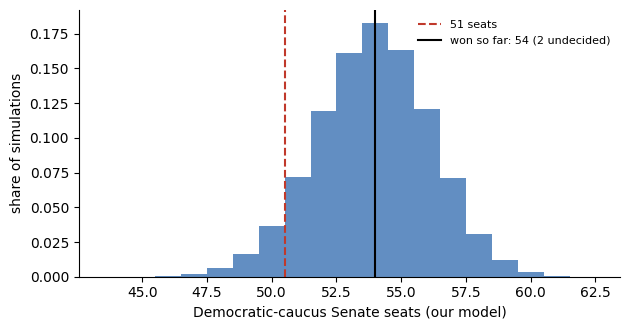

In [30]:
# seats = 34 + races with margin > 0; control at 51
seats_b = D_SAFE + (sim > 0).sum(axis=1)
p_ctrl = (seats_b >= NEED).mean()
obs_won = FACTS["d_won"]
obs_seats = D_SAFE + obs_won   # 34 + 20 = 54 caucus seats won or held so far
p_obs = (seats_b >= obs_seats).mean()
sim_i = simulate(rc.blend.values, bv, 0.0)   # no shared error
sim_i[:, rc.no_dem.values] = -100.0           # no-Democrat rule
seats_i = D_SAFE + (sim_i > 0).sum(axis=1)
print(f"Our model, {DRAWS:,} draws: P(Democratic control) = {p_ctrl:.3f}; mean seats {seats_b.mean():.1f}; 5th to 95th percentile {np.percentile(seats_b, 5):.0f} to {np.percentile(seats_b, 95):.0f}")
print(f"Observed: Democratic caucus {FACTS['w_s_di']} seats, Republicans {FACTS['w_s_r']}, {FACTS['w_s_tbd']} undecided (Alaska, Mississippi)")
print(f"Model P(at least {obs_seats} seats) = {p_obs:.3f}")
print(f"Brier score for the control outcome (one event, shown for reference and not a ranking): {(p_ctrl - 1) ** 2:.3f}")
shared_polled = np.sqrt(rho) * rc.sd[rc.poll_margin_final.notna()].mean()   # shared SD in a polled race = sqrt(rho) x its blended SD
print(f"Shared error in the polled races: about {shared_polled:.1f} points (rho = {rho:.2f}); year-level error SD in the Section 6 backtest: {ym.std():.2f} points")
print(f"With independent errors instead: P(control) = {(seats_i >= NEED).mean():.3f}, P(at least {obs_seats}) = {(seats_i >= obs_seats).mean():.3f}")

pfp = pf.copy()
pfp["senate_pD"] = pd.to_numeric(pfp.senate_pD, errors="coerce")
print("\nPlatform table (date as given in the file; rows with older or undated dates are not election-eve forecasts):")
cols = [c for c in ("platform", "date", "senate_pD", "senate_seats_D", "house_pD", "generic_ballot") if c in pfp]
show_table(pfp[cols], index=False)
ctrl = pfp[pfp.senate_pD.notna()].copy()
ctrl["brier_control"] = (ctrl.senate_pD - 1) ** 2
print("\nBrier score for Senate control (one event, shown for reference and not a ranking), for rows with a probability, and for our model:")
show_table(ctrl[["platform", "date", "senate_pD", "brier_control"]].round(3), index=False)
print(f"Our model: P = {p_ctrl:.3f}, Brier {(p_ctrl - 1) ** 2:.3f}")
# 50+1 final forecast, 3 November
fpo = ctrl[ctrl.platform.str.startswith("50+1") & ctrl.date.astype(str).str.startswith("2026-11-03")]
fpo_p = float(fpo.senate_pD.iloc[0]) if len(fpo) else float("nan")

# seat histogram; black line: observed count
fig, ax = plt.subplots(figsize=(6.4, 3.4))
bins = np.arange(seats_b.min() - 0.5, seats_b.max() + 1.5)
ax.hist(seats_b, bins=bins, density=True, color=BLUE, alpha=0.7)
ax.axvline(NEED - 0.5, color=RED, ls="--", label="51 seats")
ax.axvline(obs_seats, color="black", label=f"won so far: {obs_seats} (2 undecided)")
ax.set_xlabel("Democratic-caucus Senate seats (our model)"); ax.set_ylabel("share of simulations")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

# scorecard numbers; stop on mismatch
assert (round(p_ctrl, 3), round(seats_b.mean(), 1), round(b_all, 3), round(r_ours, 3)) == (OURS["senate_pD"], OURS["senate_seats"], OURS["race_brier33"], OURS["race_brier31"]), "update OURS in the scorecard"

**Reading the result**

- 33 called races: Brier 0.041, log loss 0.146 (always 50%: 0.250, 0.693). Favorite won 32 of 33.
- Least likely outcomes: South Carolina (0.40), Iowa (0.50), Louisiana (0.51). South Carolina is the only race where the favorite lost.
- Calibration bins hold 1 to 14 races: too few (Section 5b). Section 6 is the calibration test.

**Polled races**: 22 called races with a poll (24 polled; Alaska and Mississippi uncalled). Brier: blend 0.049, fundamentals 0.142. Polls ended 13 October to 2 November; the simple mean of each race's polls is the input.

**Ratings** (my label-to-probability mapping; 31 races, Florida and Ohio specials unrated)

- Brier: mean of five ratings 0.044, Silver Bulletin 0.035, our model 0.041.
- Ratings use candidate quality, fundraising, local polls; 11 of our 35 forecasts had no poll margin (8 unpolled, 3 with an independent). Scores depend on my mapping.

**Control**

- Our P(Democratic control) 0.938; with independent errors 0.979 (the cost of omitting the shared error).
- 50+1 final (3 November, <https://www.fiftyplusone.news/forecast/senate>): 0.79, median 53 seats. Our mean: 53.9.
- Outcome: 54 caucus seats, 2 undecided; control settled. Our P(at least 54) = 0.59.
- One outcome cannot rank forecasters or test calibration.
- 0.938 probably overconfident: shared error about 1.2 points in polled races (rho 0.08) against the Section 6 year-level SD of 6.45 points (Section 6: the Section 5 shared error is a lower estimate). A larger shared error lowers the control probability.

**Margins**: none published; computed once `result_margin` is filled and the builder rerun.

**Platforms**: only 50+1 has an election-eve control probability; older or undated ones unused; Silver Bulletin, DDHQ, NYT finals unreadable.

### Exercise E.4: scoring forecasts

- Task 1: Brier score $\frac{1}{n}\sum_i(p_i - y_i)^2$ and log loss $-\frac{1}{n}\sum_i[y_i\log p_i + (1-y_i)\log(1-p_i)]$ (Section 5b) of forecasts `E4_P` against outcomes `E4_Y` (1 = happened). Natural log.
- Task 2: ECE $= \sum_g \frac{n_g}{n}|\bar p_g - \bar y_g|$ of the Section 6 backtest (`cv.p`, `cv.win`) with 5 bins of width 0.2. Use `calib_table` or `murphy`.
- Define `brier`, `logloss`, `ece5` (4 decimals). `brier` replaces the Section 6 helper; no later cell uses it.

In [ ]:
E4_P = [0.9, 0.7, 0.2, 0.6, 0.1]   # forecast probability of each event
E4_Y = [1, 1, 0, 0, 0]               # outcome of each event
brier = None  # YOUR CODE
logloss = None  # YOUR CODE
ece5 = None  # YOUR CODE

In [ ]:
check("brier", brier, "ea00f71795c8b128", ndigits=4)
check("logloss", logloss, "dd1c1cf2ae764eb9", ndigits=4)
check("ece5", ece5, "28b3b2cad5432643", ndigits=4)

## 8. Election-night models

- Toy needle (Section 1, source 3): carry each counted county's deviation from expected to counties still out. **All numbers simulated.**

**Set-up**

- $C = 40$ counties. County $c$: expected votes $v_c$, baseline margin $b_c$ (points), urbanness $x_c$ (mean 0, SD 1; urban leans D).
- True county margin:

$$ m_c = b_c + S + B\,x_c + e_c, $$

- $S \sim N(0, 3^2)$: statewide swing. $B \sim N(0, 2^2)$: urban swing. $e_c \sim N(0, 5^2)$: county noise.
- Statewide margin: $m = \sum_c v_c m_c / V$, $V = \sum_c v_c$.

**Estimator**

- Reported: $r_c = m_c - b_c$; fit $r_c = a + B x_c + e_c$ by conjugate normal (closed-form Bayes) update, noise SD 5.
- Posterior of $\beta = (a, B)$: $\Sigma = (P_0 + X^\top X/\tau^2)^{-1}$, $\beta$-mean $\mu = \Sigma X^\top r/\tau^2$. $X$: rows $(1, x_c)$ of reported counties; $P_0$: prior precisions $1/3^2$, $1/2^2$; $\tau = 5$.
- Outstanding: $m_c = b_c + a + B x_c$, plus uncertainty from $(a, B)$ and $e_c$.
- Statewide = reported + predicted outstanding, $w_c = v_c/V$: $\hat m = \sum_{c\in R} w_c m_c + \sum_{c\in O} w_c\,(b_c + X_c\mu)$.
- Variance: $\sum_{c\in O} w_c X_c\,\Sigma\,\sum_{c\in O} w_c X_c^\top + \tau^2\sum_{c\in O} w_c^2$. Win probability $= P(\text{statewide} > 0) = \Phi(\hat m/\sqrt{\text{variance}})$.
- "Swing only": drops $B x_c$.

- Two simulated nights, two estimators.

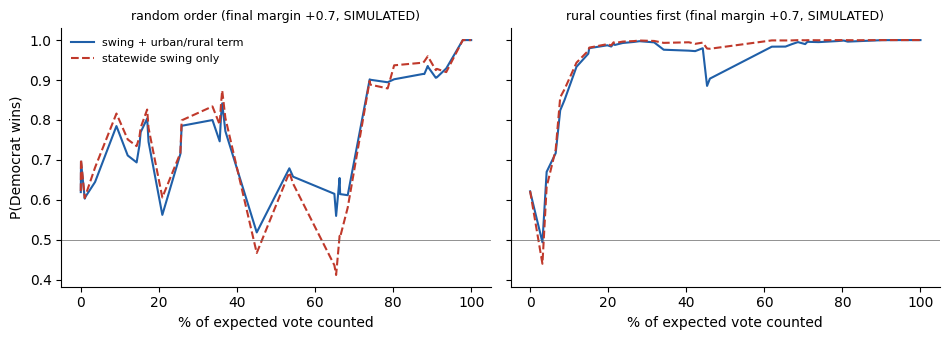

random order: final margin +0.73; win probability at 0%, 25%, 50%, 75%, 100% counted: 0.62, 0.71, 0.68, 0.89, 1.00
rural counties first: final margin +0.69; win probability at 0%, 25%, 50%, 75%, 100% counted: 0.62, 1.00, 0.98, 1.00, 1.00


In [33]:
TAU, PRIOR_S, PRIOR_B = 5.0, 3.0, 2.0  # county noise SD, swing prior SDs (made up)
C = 40


def make_night(rng, rural_first):
    """One simulated state: county urbanness x, expected votes v, baseline b, true margins m, reporting order."""
    x = rng.normal(size=C)
    v = rng.lognormal(9.5, 1.2, size=C)
    b = 6.0 * x
    b = b - (v * b).sum() / v.sum() + 1.0  # statewide baseline margin D+1.0
    S, B = rng.normal(0, PRIOR_S), rng.normal(0, PRIOR_B)   # statewide swing and urban-rural swing
    mc = b + S + B * x + rng.normal(0, TAU, size=C)
    key = x + rng.normal(0, 1.0, size=C) if rural_first else rng.normal(size=C)
    order = np.argsort(key)  # rural_first: low x reports first
    return dict(x=x, v=v, b=b, m=mc, order=order, final=(v * mc).sum() / v.sum())


def win_prob(night, k, use_type=True):
    """Win probability and estimated final margin after the first k counties have reported."""
    # reported counties (idx_r) and outstanding counties (idx_o)
    idx_r, idx_o = night["order"][:k], night["order"][k:]
    v, b, m, x = night["v"], night["b"], night["m"], night["x"]
    V = v.sum()
    rep = (v[idx_r] * m[idx_r]).sum() / V
    # design: constant, + urbanness if use_type
    cols = (lambda z: np.column_stack([np.ones_like(z), z])) if use_type else (lambda z: np.ones((len(z), 1)))
    P0 = np.diag([1 / PRIOR_S ** 2, 1 / PRIOR_B ** 2][: (2 if use_type else 1)])
    # conjugate normal update for (a, B)
    if k > 0:
        X = cols(x[idx_r]); r = m[idx_r] - b[idx_r]
        Sig = np.linalg.inv(P0 + X.T @ X / TAU ** 2)
        mu = Sig @ X.T @ r / TAU ** 2
    else:
        Sig, mu = np.linalg.inv(P0), np.zeros(P0.shape[0])
    # final = reported + predicted outstanding; var: parameters + county noise
    Xo = cols(x[idx_o]); w = v[idx_o] / V
    est = rep + (w * (b[idx_o] + Xo @ mu)).sum()
    var = (w @ Xo) @ Sig @ (w @ Xo) + TAU ** 2 * (w ** 2).sum()
    return stats.norm.cdf(est / np.sqrt(var)), est


def track(night, use_type=True):
    """Share of vote counted, win probability and margin estimate after each county."""
    share = np.cumsum(night["v"][night["order"]]) / night["v"].sum()
    ks = np.arange(0, C + 1, 1)
    out = [win_prob(night, k, use_type) for k in ks]
    return np.r_[0, share][ks], np.array([o[0] for o in out]), np.array([o[1] for o in out])


# one close night for each reporting order
rng = np.random.default_rng(8)
nights = {}
for name, rf in (("random order", False), ("rural counties first", True)):
    while True:  # pick a close night (SIMULATED)
        nt = make_night(rng, rf)
        if 0.3 < nt["final"] < 1.5:
            break
    nights[name] = nt

# win probability against share counted
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.5), sharey=True)
for ax, (name, nt) in zip(axes, nights.items()):
    s1, p1, e1 = track(nt, True)
    s0, p0, e0 = track(nt, False)
    ax.plot(100 * s1, p1, color=BLUE, label="swing + urban/rural term")
    ax.plot(100 * s0, p0, color=RED, ls="--", label="statewide swing only")
    ax.axhline(0.5, color=GREY, lw=0.5)
    ax.set_title(f"{name} (final margin {nt['final']:+.1f}, SIMULATED)", fontsize=9)
    ax.set_xlabel("% of expected vote counted")
axes[0].set_ylabel("P(Democrat wins)"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
for name, nt in nights.items():
    s1, p1, e1 = track(nt, True)
    print(f"{name}: final margin {nt['final']:+.2f}; win probability at 0%, 25%, 50%, 75%, 100% counted: " +
          ", ".join(f"{p1[min(np.searchsorted(s1, q), len(s1) - 1)]:.2f}" for q in (0.0, 0.25, 0.5, 0.75, 1.0)))

- Win probability reaches 0 or 1 at full count.
- Rural first: swing-only is pulled by rural counties; the urban/rural term is less biased early.
- One night proves little: 300 repeats next.

- 300 nights per reporting order; estimators at 25%, 50%, 75% counted.
- Error: mean over nights of $|\hat m - m^{final}|$. Confident: $P > 0.95$ or $P < 0.05$; confident and wrong: confident with the sign opposite to $m^{final}$.

In [34]:
# 300 states per order; errors and confident calls
rng = np.random.default_rng(80)
rows = []
for night_id in range(300):
    for rf in (False, True):
        nt = make_night(rng, rf)
        # checkpoints: 25%, 50%, 75% counted
        for q in (0.25, 0.5, 0.75):
            share = np.cumsum(nt["v"][nt["order"]]) / nt["v"].sum()
            k = int(np.searchsorted(share, q)) + 1
            for ut in (True, False):   # with and without the urban/rural term
                p, e = win_prob(nt, k, ut)
                rows.append(dict(order="rural first" if rf else "random", share=q, type_term=ut, abs_err=abs(e - nt["final"]),
                                 conf_wrong=((p > .95) and nt["final"] < 0) or ((p < .05) and nt["final"] > 0),
                                 conf=(p > .95) or (p < .05)))
sim8 = pd.DataFrame(rows)
tab8 = sim8.groupby(["order", "share", "type_term"]).agg(mean_abs_error=("abs_err", "mean"), share_confident=("conf", "mean"),
                                                          share_confident_and_wrong=("conf_wrong", "mean")).round(3)
print("300 simulated states per row group (all SIMULATED).  Confident means a win probability above 0.95 or below 0.05.")
show_table(tab8, index=True)

300 simulated states per row group (all SIMULATED).  Confident means a win probability above 0.95 or below 0.05.


**Reading the table** (300 simulated states; mean absolute error at half the vote counted)

- Random order: 0.71 points with the urban/rural term, 0.78 without.
- Rural first: 0.87 with, 1.13 without.
- Confident wrong calls: the cost of an overconfident estimator.

**A toy**: real needles face partial counties, mail ballots, richer demographics. Calls come from the AP or desks; the NYT says the needle is not a call tool (Section 1, source 3).

**Chain**: poll average, fundamentals, blend, shared-error simulation, backtest, backcast, live update. The shared error is most often left out.

## 9. Texas governor: polls, model and market

- Greg Abbott (R, incumbent) against Gina Hinojosa (D): poll model, Polymarket, Kalshi. From Polson and Sokolov, "The Mathematics of Election Night" and "Are Polymarket Odds Efficient?".

**Convention switch (Sections 9 to 11)**

- Abbott's two-party share replaces the margin. Contract: "Abbott wins"; share above 50% = Abbott win.
- Two-party share: Abbott / (Abbott + Hinojosa). Abbott 48, Hinojosa 46: 48/94 = 51.1%.
- 1 point of share = 2 points of margin: Abbott 46% = D+8.

**Model: state space poll average** (hidden true share, seen through noisy polls)

- $\theta_t$: Abbott's share on day $t$, a random walk:
$$ \theta_t = \theta_{t-1} + \eta_t, \qquad \eta_t \sim N(0, \sigma_\eta^2). $$
- Poll $k$ by pollster $f(k)$ on day $t$:
$$ y_k = \theta_t + h_{f(k)} + r\,\mathrm{RV}_k + \epsilon_k, \qquad \epsilon_k \sim N\!\left(0,\ \tfrac{y_k(1-y_k)}{n_k} + \tau^2\right). $$
- $h_f$: house effect (prior SD 1.5 points). $\mathrm{RV}_k$: 1 registered-voter poll, 0 likely-voter poll; $r$: its effect.
- $\tau$: non-sampling error, beyond the sampling noise $y_k(1-y_k)/n_k$.
- $\sigma_\eta^2$ (`q` in the code): daily random-walk variance.
- Kalman filter: updates $\theta_t$, gives the likelihood. $\sigma_\eta^2$, $\tau$: maximum likelihood on a grid.
- Silver's iterated house effects: same idea by backfitting (ridge regression).

- 44 public polls, January to late October. Share = Abbott / (Abbott + Hinojosa).

In [35]:
# --- Texas governor polls, 2026 (Polson and Sokolov, polls_table.tex)
TX_POLLS = """Verasight|10/23|601|LV|48|46
Texas Public Opinion Research|10/23|969|LV|51|48
Emerson|10/22|1000|LV|51|47
New River GSG|10/21|934|LV|48|46
ActiVote|10/21|400|LV|53|48
Fox News|10/21|1398|LV|52|47
UH Hobby|10/19|2000|LV|49|46
YouGov|10/18|1460|LV|52|48
ActiVote|10/15|400|LV|51|49
YouGov|10/14|861|LV|48|49
Marist|10/14|1196|LV|49|45
Siena|10/13|617|LV|48|47
UMass Lowell|10/08|850|LV|48|44
Guidant|10/07|800|LV|46|44
YouGov|10/06|3622|LV|47|48
Siena|10/04|615|LV|46|49
Fox News|10/01|881|LV|52|47
Texas Public Opinion Research|9/25|1007|LV|50|46
Marist|9/23|1139|RV|46|49
Texas Southern|9/22|1800|LV|49|45
Emerson|9/17|1000|LV|49|46
Siena|9/17|614|LV|45|49
Mason Dixon|9/15|625|LV|48|41
AARP|9/10|895|LV|49|46
N+ Univision|9/09|1000|LV|47|47
Overton|9/02|1167|LV|47|46
Texas Public Opinion Research|8/27|1000|LV|49|42
Univ of Texas|8/25|1200|RV|45|40
Emerson|8/13|1000|LV|49|45
Texas Pulse|8/07|619|LV|46|45
Texas Southern|8/04|1200|LV|49|43
Fox News|7/30|1006|RV|50|49
Texas Public Opinion Research|7/28|1048|LV|45|42
Siena|6/30|656|LV|51|44
Univ of Texas|6/23|1200|RV|47|40
Texas Pulse|6/09|807|LV|49|44
Quantus|6/05|800|LV|49|41
Texas Public Opinion Research|5/29|1670|LV|46|41
Texas Southern|5/18|1223|LV|49|43
Univ of Texas|4/29|1200|RV|44|38
Texas Public Opinion Research|4/28|1865|LV|48|43
UT Tyler|2/27|959|LV|49|41
Univ of Houston|2/11|1502|LV|49|42
Emerson|1/15|1165|LV|50|42"""
tx = pd.read_csv(io.StringIO(TX_POLLS), sep="|", names=["firm", "date", "n", "pop", "abbott", "hinojosa"])
tx["date"] = pd.to_datetime("2026/" + tx.date)
tx["day"] = (tx.date - pd.Timestamp("2026-01-01")).dt.days      # day of the year, 0 = 1 January
tx["share"] = tx.abbott / (tx.abbott + tx.hinojosa)                # Abbott two-party share
tx["rv"] = (tx["pop"] == "RV").astype(float)                       # registered-voter poll
tx = tx.sort_values("day").reset_index(drop=True)
firms = sorted(tx.firm.unique()); tx["fid"] = tx.firm.map({f: i for i, f in enumerate(firms)})
E_DAY = (pd.Timestamp("2026-11-03") - pd.Timestamp("2026-01-01")).days
print(f"{len(tx)} polls from {len(firms)} pollsters; mean Abbott two-party share {tx.share.mean():.3f}")

44 polls from 22 pollsters; mean Abbott two-party share 0.519


- Filter; fit $\sigma_\eta^2$ (`q`) and $\tau$; election-day win probability. Forecast SD adds 2.5 points for the final polling miss (assumption: typical state polling error). Plot: polls, smoothed trend, two-SD band.
- State $x = (\theta, h_1, \dots, h_F, r)$; poll $k$ has vector $z$ ($z_\theta = 1$, $z_{f(k)} = 1$, $z_r = \mathrm{RV}_k$), variance $R_k = y_k(1-y_k)/n_k + \tau^2$. Share $y_k = A_k/(A_k + H_k)$.
- Each day: $V_{\theta\theta} \leftarrow V_{\theta\theta} + \sigma_\eta^2$. Each poll: $S = z^\top V z + R_k$, $K = Vz/S$, $x \leftarrow x + K(y_k - z^\top x)$, $V \leftarrow V - K z^\top V$. Log likelihood $= \sum_k \log N(y_k - z^\top x;\ 0,\ S)$.
- Forecast: $\sigma_{tot}^2 = \sigma_E^2 + 0.025^2$ ($\sigma_E$: filter SD on election day). Normal: $P = \Phi\bigl((\hat\theta_E - \tfrac12)/\sigma_{tot}\bigr)$. Student-t, $\nu = 5$: $P = F_\nu\bigl((\hat\theta_E - \tfrac12)/(\sigma_{tot}\sqrt{(\nu-2)/\nu})\bigr)$.

MLE: drift SD 0.08 points per day, non-sampling SD 0.0 points
Election-day estimate: Abbott 51.7% of the two-party vote (filter SD 0.6, total SD 2.6)
P(Abbott wins): normal 0.744, Student-t with 5 df 0.782
Largest house effects (points of Abbott share): YouGov -1.3, Siena -1.2, Mason Dixon +0.8, Univ of Texas +1.7


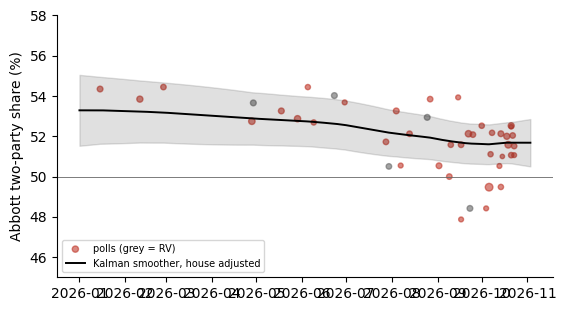

In [36]:
F = len(firms)
DIM = 2 + F    # state: [theta, house effects, RV effect]


def kalman(q, tau, smooth=False):
    """Kalman filter for the poll model; returns the log likelihood, or the filtered and smoothed paths.
    q = daily variance of the random walk in theta, tau = non-sampling poll error SD."""
    m = np.zeros(DIM); m[0] = 0.53
    V = np.diag([0.05**2] + [0.015**2] * F + [0.02**2])   # prior SDs: theta 5 pts, house 1.5 pts, RV 2 pts
    ll, mf, Vf, mp, Vp = 0.0, [], [], [], []
    by_day = tx.groupby("day").indices
    for d in range(E_DAY + 1):
        if d > 0:
            V = V.copy(); V[0, 0] += q                     # predict: theta drifts, house effects stay put
        mp.append(m.copy()); Vp.append(V.copy())
        for k in by_day.get(d, []):                        # update per poll
            r = tx.iloc[k]
            z = np.zeros(DIM); z[0] = 1; z[1 + r.fid] = 1; z[-1] = r.rv
            R = r.share * (1 - r.share) / r.n + tau**2       # sampling + non-sampling variance
            S = z @ V @ z + R; e = r.share - z @ m; K = V @ z / S
            ll += stats.norm.logpdf(e, 0, np.sqrt(S)); m = m + K * e; V = V - np.outer(K, z @ V)
        mf.append(m.copy()); Vf.append(V.copy())
    if not smooth:
        return ll
    ms, Vs = [None] * len(mf), [None] * len(mf); ms[-1], Vs[-1] = mf[-1], Vf[-1]
    for d in range(len(mf) - 2, -1, -1):                   # Rauch-Tung-Striebel smoother
        J = Vf[d] @ np.linalg.inv(Vp[d + 1])
        ms[d] = mf[d] + J @ (ms[d + 1] - mp[d + 1]); Vs[d] = Vf[d] + J @ (Vs[d + 1] - Vp[d + 1]) @ J.T
    return np.array(mf), np.array(Vf), np.array(ms), np.array(Vs)


# fit q and tau by maximum likelihood on a grid
q_sd = np.array([.0003, .0005, .0008, .0012, .002]); taus = np.array([0, .0025, .005, .01, .015, .02, .025])
LL = np.array([[kalman(q**2, t) for t in taus] for q in q_sd])
i, j = np.unravel_index(LL.argmax(), LL.shape); Q_HAT, TAU_HAT = q_sd[i]**2, taus[j]
mf, Vf, ms, Vs = kalman(Q_HAT, TAU_HAT, smooth=True)
theta_E, sd_E = mf[-1][0], np.sqrt(Vf[-1][0, 0])
SE_ERR = 0.025                                    # final polling miss SD (assumption)
sd_tot = np.sqrt(sd_E**2 + SE_ERR**2)
P_ABBOTT = stats.norm.cdf((theta_E - .5) / sd_tot)
NU = 5; P_ABBOTT_T = stats.t.cdf((theta_E - .5) / (sd_tot * np.sqrt((NU - 2) / NU)), NU)
print(f"MLE: drift SD {np.sqrt(Q_HAT)*100:.2f} points per day, non-sampling SD {TAU_HAT*100:.1f} points")
print(f"Election-day estimate: Abbott {theta_E*100:.1f}% of the two-party vote (filter SD {sd_E*100:.1f}, total SD {sd_tot*100:.1f})")
print(f"P(Abbott wins): normal {P_ABBOTT:.3f}, Student-t with 5 df {P_ABBOTT_T:.3f}")
house = pd.Series(ms[-1][1:1 + F] * 100, index=firms).sort_values()
print("Largest house effects (points of Abbott share):", ", ".join(f"{k} {v:+.1f}" for k, v in pd.concat([house.head(2), house.tail(2)]).items()))

days = pd.date_range("2026-01-01", periods=E_DAY + 1)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.scatter(tx.date, tx.share * 100, s=np.sqrt(tx.n) / 2, c=np.where(tx.rv == 1, GREY, RED), alpha=.6, label="polls (grey = RV)")
sdp = np.sqrt(Vs[:, 0, 0]); ax.plot(days, ms[:, 0] * 100, "k", lw=1.4, label="Kalman smoother, house adjusted")
ax.fill_between(days, (ms[:, 0] - 2 * sdp) * 100, (ms[:, 0] + 2 * sdp) * 100, color="k", alpha=.12)
ax.axhline(50, c=GREY, lw=.6); ax.set_ylim(45, 58); ax.set_ylabel("Abbott two-party share (%)"); ax.legend(fontsize=7, loc="lower left")
plt.show()
assert round(P_ABBOTT, 3) == OURS["tx_abbott"], "update OURS in the scorecard"

**Reading the result**

- Election day: Abbott 51.7% of the two-party vote, total SD 2.6 points.
- P(Abbott wins): 0.744 normal, 0.782 Student-t (5 df). Same variance: fat tails favor the favorite in a close race.
- Non-sampling SD 0 (edge of the grid): no spread beyond sampling. Weak herding hint (p = 0.12, Texas paper).
- House effects at most about 1.7 points.

**Price as a forecast**

- Binary option on $\theta > \tfrac12$: $p = \Phi\big((\hat\theta - \tfrac12)/\sigma\big)$.
- Market-implied SD ("implied volatility"), at the poll center: $\sigma = (\hat\theta - \tfrac12)/\Phi^{-1}(p)$.
- Partial count: $A = V_A/(V_A + V_H)$ (votes). Miss $= \hat\theta_E - A$; in SDs: miss$/\sigma$ ($\sigma$: model or market). Tail probability $= 1 - \Phi(\text{miss}/\sigma)$.
- **Prices.** Polymarket: 0.618 at 7:50 AM CT, 0.663 at 5:13 PM CT, 3 November (before Texas polls closed). Kalshi: 0.60, no time given.
- **Partial count; scores provisional.** Count of 9:13 PM ET, 3 November, from the Polymarket paper, source not named (not verified).
- Early counts are biased (Section 11): Abbott's final share probably above 43.2%. The cell also shows the paper's 46% caveat.

Market-implied forecast SD: 4.0 points (our model: 2.6)
Partial count: Abbott 43.2% of the two-party vote, so Hinojosa leads
Miss: 8.5 points = 3.3 model SDs = 2.1 market SDs
Tail probability of a miss this large: model 0.0005, market 0.0172
If Abbott's final two-party share is 46% instead: miss 5.7 points = 1.4 market SDs = 2.2 model SDs


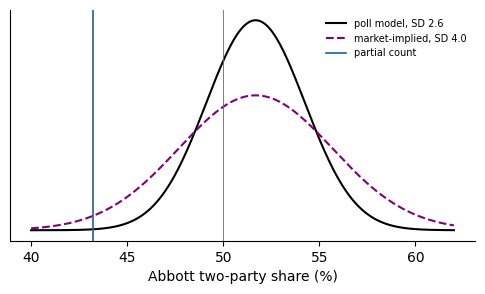

In [37]:
# Market prices and the outcome, as reported in Polson and Sokolov, "Are Polymarket Odds Efficient?" (4 November 2026)
TX = dict(polymarket_open=0.618, polymarket_close=0.663,   # Polymarket P(Abbott): 7:50 AM CT and 5:13 PM CT on 3 Nov
          kalshi=0.60,                                     # Kalshi P(Abbott); the source gives no time for it
          abbott_votes=1_861_331, hinojosa_votes=2_444_456) # PARTIAL count of 9:13 PM ET on 3 Nov, source not named in the paper (not verified)
sig_mkt = (theta_E - .5) / stats.norm.ppf(TX["polymarket_close"])   # implied SD: solve p = Phi((theta - 0.5) / sigma)
A_share = TX["abbott_votes"] / (TX["abbott_votes"] + TX["hinojosa_votes"])
err = theta_E - A_share
print(f"Market-implied forecast SD: {sig_mkt*100:.1f} points (our model: {sd_tot*100:.1f})")
print(f"Partial count: Abbott {A_share*100:.1f}% of the two-party vote, so Hinojosa leads")
print(f"Miss: {err*100:.1f} points = {err/sd_tot:.1f} model SDs = {err/sig_mkt:.1f} market SDs")
print(f"Tail probability of a miss this large: model {stats.norm.sf(err/sd_tot):.4f}, market {stats.norm.sf(err/sig_mkt):.4f}")
alt = 0.46   # paper's caveat: partial count, final share above 43.2%
print(f"If Abbott's final two-party share is {alt*100:.0f}% instead: miss {(theta_E-alt)*100:.1f} points = {(theta_E-alt)/sig_mkt:.1f} market SDs = {(theta_E-alt)/sd_tot:.1f} model SDs")

g = np.linspace(.40, .62, 400)
fig, ax = plt.subplots(figsize=(6.0, 3.0))
ax.plot(g * 100, stats.norm.pdf(g, theta_E, sd_tot), "k", label=f"poll model, SD {sd_tot*100:.1f}")
ax.plot(g * 100, stats.norm.pdf(g, theta_E, sig_mkt), c="purple", ls="--", label=f"market-implied, SD {sig_mkt*100:.1f}")
ax.axvline(A_share * 100, c=BLUE, lw=1.2, label="partial count"); ax.axvline(50, c=GREY, lw=.6)
ax.set_xlabel("Abbott two-party share (%)"); ax.set_yticks([]); ax.legend(fontsize=7, frameon=False)
plt.show()

**Reading the result**

- Implied SD: market 4.0 points, model 2.6.
- Partial count (9:13 PM ET, 3 November): Abbott 43.2%; Hinojosa leads.
- Miss 8.5 points: 3.3 model SDs, 2.1 market SDs. Probability of a miss this large: 0.0005 (model), 0.0172 (market).
- Paper's caveat: "If Abbott's final two party share is 46%, the error is 1.4 market sd and 2.2 model sd; the ranking of forecasts is unchanged for any final share below 50%." The cell agrees: at 46%, miss 5.7 points.
- Market's wider spread fit better; ranking holds unless Abbott reaches 50%.

## 10. Polymarket efficiency

**Three meanings of "efficient"**

- Martingale: price = expected outcome given public information.
- Calibration (Section 5b): $E[Y \mid p] = p$.
- No edge: no public-information forecast beats the price in expected log score.

**Why a price need not be a probability**

- Log-utility traders: price = wealth-weighted mean belief (Wolfers and Zitzewitz).
- Distortions: favorite-longshot bias (longshots overpriced), wealth correlated with outcomes, idle collateral, fees.

**Method: logistic recalibration**

- Fit $\operatorname{logit} P(Y=1) = a + b\,\operatorname{logit} p$ on resolved markets; $p$ price, $Y$ = 1 if YES.
- Calibration: $(a, b) = (0, 1)$; likelihood ratio test, $\chi^2_2$.
- $a \neq 0$: YES mispriced. $b < 1$: too extreme; $b > 1$: too timid. Plus Murphy decomposition.
- Likelihood: bin $g$ has $n_g$ markets, $k_g$ YES, price $p_g$ (midpoint); $q_g = \operatorname{expit}(a + b\operatorname{logit}p_g)$; $\ell(a,b) = \sum_g [k_g\log q_g + (n_g - k_g)\log(1 - q_g)]$.
- Test: $\mathrm{LR} = 2[\ell(\hat a,\hat b) - \ell(0,1)] \sim \chi^2_2$. Pearson: $\chi^2 = \sum_g (k_g - n_g p_g)^2/(n_g p_g(1 - p_g))$, 9 interior bins.
- Murphy (Section 5b) over bins: $\mathrm{REL} = \sum_g \frac{n_g}{n}(p_g - k_g/n_g)^2$, $\mathrm{RES} = \sum_g \frac{n_g}{n}(k_g/n_g - \bar y)^2$.
- Data: 7,601 resolved Polymarket markets, 11 price bins (LessWrong, April 2026). Bin midpoints as prices, so the two end bins are not tested.

Markets: 7601; interior bins: 699 markets, 279 YES against 237 expected
Recalibration: a = 0.46 (SE 0.12), b = 1.10 (SE 0.09)
Test of calibration (a, b) = (0, 1): LR chi2(2) = 17.5, p = 0.0002; Pearson chi2(9) = 22.8, p = 0.007
At a price of 0.50 the recalibrated probability is 0.61
Largest Pearson term: price bin 0.65 to 0.75 (YES rate 0.965) contributes 9.7 of 22.8
Murphy decomposition of the Brier score: reliability 0.001, resolution 0.143, uncertainty 0.158


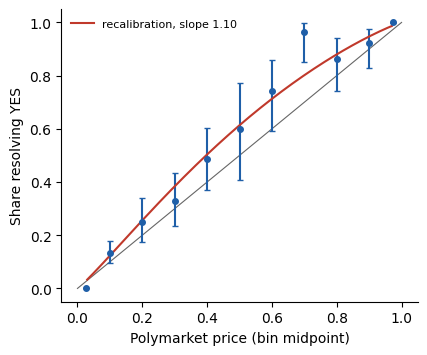

In [38]:
# Calibration of 7,601 resolved Polymarket binary markets: count and YES rate in each price bin
# (LessWrong analysis, April 2026, as tabulated in Polson and Sokolov).  Bin midpoints stand in for prices.
lo = np.array([0, .05, .15, .25, .35, .45, .55, .65, .75, .85, .95]); hi = np.r_[lo[1:], 1]
n_b = np.array([5693, 254, 104, 82, 70, 25, 39, 29, 44, 52, 1209])
yes_rate = np.array([.001, .134, .25, .329, .486, .60, .744, .965, .864, .923, 1.0])
k_b = np.round(n_b * yes_rate).astype(int); mid = (lo + hi) / 2
inner = slice(1, 10)                                    # the nine interior bins, 5% to 95%
nm, km, pm = n_b[inner], k_b[inner], mid[inner]
logit = lambda p: np.log(p / (1 - p))


def nll(th):
    """Negative log likelihood of logit P(YES) = a + b logit(price), grouped binomial counts."""
    q = 1 / (1 + np.exp(-(th[0] + th[1] * logit(pm))))
    return -(km * np.log(q) + (nm - km) * np.log(1 - q)).sum()


from scipy.optimize import minimize
fitc = minimize(nll, [0, 1]); a_hat, b_hat = fitc.x; se_a, se_b = np.sqrt(np.diag(fitc.hess_inv))
lr = 2 * (nll([0, 1]) - fitc.fun)
pear = ((km - nm * pm) ** 2 / (nm * pm * (1 - pm))).sum()
print(f"Markets: {n_b.sum()}; interior bins: {nm.sum()} markets, {km.sum()} YES against {nm @ pm:.0f} expected")
print(f"Recalibration: a = {a_hat:.2f} (SE {se_a:.2f}), b = {b_hat:.2f} (SE {se_b:.2f})")
print(f"Test of calibration (a, b) = (0, 1): LR chi2(2) = {lr:.1f}, p = {stats.chi2.sf(lr, 2):.4f}; Pearson chi2(9) = {pear:.1f}, p = {stats.chi2.sf(pear, 9):.3f}")
print(f"At a price of 0.50 the recalibrated probability is {1/(1+np.exp(-a_hat)):.2f}")
terms = (km - nm * pm) ** 2 / (nm * pm * (1 - pm)); big = int(terms.argmax())   # each bin's share of the Pearson statistic
print(f"Largest Pearson term: price bin {lo[inner][big]:.2f} to {hi[inner][big]:.2f} (YES rate {yes_rate[inner][big]:.3f}) contributes {terms[big]:.1f} of {pear:.1f}")
Yb = k_b / n_b; ybar = k_b.sum() / n_b.sum()
rel = (n_b * (mid - Yb) ** 2).sum() / n_b.sum(); res = (n_b * (Yb - ybar) ** 2).sum() / n_b.sum()
print(f"Murphy decomposition of the Brier score: reliability {rel:.3f}, resolution {res:.3f}, uncertainty {ybar*(1-ybar):.3f}")

ci = np.array([stats.beta.ppf([.025, .975], k + .5, n - k + .5) for k, n in zip(k_b, n_b)])   # Jeffreys intervals
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ax.plot([0, 1], [0, 1], c=GREY, lw=.8)
ax.errorbar(mid, yes_rate, yerr=[np.clip(yes_rate - ci[:, 0], 0, 1), np.clip(ci[:, 1] - yes_rate, 0, 1)], fmt="o", c=BLUE, ms=4, capsize=2)
gg = np.linspace(.03, .97, 200); ax.plot(gg, 1 / (1 + np.exp(-(a_hat + b_hat * logit(gg)))), c=RED, label=f"recalibration, slope {b_hat:.2f}")
ax.set_xlabel("Polymarket price (bin midpoint)"); ax.set_ylabel("Share resolving YES"); ax.legend(fontsize=8, frameon=False)
plt.show()

**Reading the result**

- $b = 1.10$: consistent with 1 (neither too extreme nor too timid).
- $a = 0.46$: calibration rejected, $p = 0.0002$ (Pearson: $p = 0.007$).
- Price 0.50: recalibrated 0.61, so YES is underpriced mid-range. Interior bins: 279 YES against 237 expected.
- Rejection leans on one bin, 0.65 to 0.75 (YES rate 0.965): 9.7 of the Pearson 22.8.
- REL 0.001 against RES 0.143: miscalibration real but cheap.
- Calibration is not accuracy or profit; edge test below.

**Next cell**

- Midterms: exact Poisson interval for the expected number of upsets $U$ (upset: favorite lost): $[\tfrac12\chi^2_{0.025}(2U),\ \tfrac12\chi^2_{0.975}(2U+2)]$. Mean favorite price consistent with it: $[1 - u_{hi}/N,\ 1 - u_{lo}/N]$.
- Texas, partial count (provisional): log score (-log of the probability given to what happened; lower better) and Brier per forecast. Abbott lost: log score $= -\log(1 - P)$, Brier $= P^2$.
- Bayes factor: market's probability of what happened / model's. Above 1 favors the market. $\mathrm{BF} = (1 - p_{mkt})/(1 - p_{model})$.
- Kelly, poll-model believer against the market: $f^* = (q-p)/(1-p)$ ($q$ own, $p$ price); log growth if Abbott wins $\log(1 - f + f/p)$, if he loses $\log(1 - f)$; expected $\mu = q\cdot\text{win} + (1 - q)\cdot\text{lose} = \mathrm{KL}(q\,\|\,p)$ if $q$ right; SD $s = \sqrt{q(1-q)}\,(\text{win} - \text{lose})$; races needed at $t = 2$: $n \approx (2s/\mu)^2$.

In [39]:
# favorites won 479 of 487 Kalshi race contracts (RotoWire, via Polson and Sokolov)
U, N_C = 8, 487
lo_u, hi_u = stats.chi2.ppf(.025, 2 * U) / 2, stats.chi2.ppf(.975, 2 * U + 2) / 2   # exact Poisson interval for E[U]
print(f"Upsets: {U} of {N_C}. Exact 95% interval for the expected number: [{lo_u:.1f}, {hi_u:.1f}]")
print(f"Consistent with calibration if the average favorite price was between {1-hi_u/N_C:.3f} and {1-lo_u/N_C:.3f}")

# Texas scores, PROVISIONAL: Hinojosa leads the partial count of 9:13 PM ET, 3 Nov
fc = {"Kalshi": TX["kalshi"], "Polymarket, start of day": TX["polymarket_open"], "Polymarket, end of day": TX["polymarket_close"],
      "Kalman poll model (Section 9)": P_ABBOTT, "Kalman, Student-t (Section 9)": P_ABBOTT_T}
tab = pd.DataFrame({"P(Abbott)": fc}).assign(**{"log score": lambda d: -np.log(1 - d["P(Abbott)"]), "Brier": lambda d: d["P(Abbott)"] ** 2})
print("Texas scores are provisional: they use the partial count of 9:13 PM ET on 3 November.")
show_table(tab.round(3), index=True)
print(f"Bayes factor, market over poll model: {(1-TX['polymarket_close'])/(1-P_ABBOTT):.2f}")

# Kelly: poll-model believer (q) bets on Abbott at price p
q, p = P_ABBOTT, TX["polymarket_close"]
f = (q - p) / (1 - p)                                         # Kelly fraction of wealth staked on Abbott
win, lose = np.log(1 - f + f / p), np.log(1 - f)              # log growth if Abbott wins / loses
mu = q * win + (1 - q) * lose                                 # expected log growth = KL(q || p)
s = np.sqrt(q * (1 - q)) * (win - lose)
print(f"Kelly stake {f:.3f}; realized log return {lose:.3f}; expected growth {mu:.3f} nats per race, SD {s:.3f}")
print(f"Races needed to detect an edge this size at t = 2: about {(2*s/mu)**2:.0f}")

Upsets: 8 of 487. Exact 95% interval for the expected number: [3.5, 15.8]
Consistent with calibration if the average favorite price was between 0.968 and 0.993
Texas scores are provisional: they use the partial count of 9:13 PM ET on 3 November.


,P(Abbott),log score,Brier
Kalshi,0.6,0.916,0.36
"Polymarket, start of day",0.618,0.962,0.382
"Polymarket, end of day",0.663,1.088,0.44
Kalman poll model (Section 9),0.744,1.362,0.553
"Kalman, Student-t (Section 9)",0.782,1.522,0.611


Bayes factor, market over poll model: 1.32
Kelly stake 0.240; realized log return -0.274; expected growth 0.015 nats per race, SD 0.170
Races needed to detect an edge this size at t = 2: about 493


**Reading the result**

- Favorites won 479 of 487 race contracts. Eight upsets fit calibration if the mean favorite price was 0.968 to 0.993 (plausible for mostly safe seats). A real test needs race-by-race prices.
- Texas (partial count, provisional): both markets beat the poll model on log score and Brier.
- Bayes factor, market over model: 1.32. One race: weak evidence.
- Kelly trader: staked 0.240 of wealth on Abbott, lost 0.274 in log wealth (partial count).
- Edge 0.015 nats per race, SD 0.170: about 493 independent races to detect.

**Verdict**

- Nearly calibrated; better than the poll model in Texas on the partial count (provisional).
- Not strictly efficient: YES underpriced mid-range.
- One upset can neither convict nor acquit a price.

### Exercise E.5: edge and Kelly stake

- A contract pays $1 if the event happens. Price p = `E5_PRICE` = 0.40; your probability q = `E5_Q` = 0.55.
- Edge (expected profit per contract, in dollars) = q(1 - p) - (1 - q)p.
- Kelly fraction = edge / (1 - p), as in Lab 8.
- Define `edge` (dollars per contract) and `kelly_f` (share of wealth, 0 to 1). 4 decimals.

In [ ]:
E5_PRICE, E5_Q = 0.40, 0.55   # market price in dollars of a contract that pays $1; your probability of the event
edge = None  # YOUR CODE
kelly_f = None  # YOUR CODE

In [ ]:
check("edge", edge, "8410b845956e3880", ndigits=4)
check("kelly_f", kelly_f, "2f1b3a9240f17763", ndigits=4)

## 11. Calling a race after the polls close

- How early to call when the counted precincts are not a random sample: early votes first, rural counties before Harris and Dallas.
- Each system conditions on something so reporting order stops mattering.

**Terms**

- Early versus election-day gap: a candidate's share difference between the two votes.
- Stratum: group of similar areas.
- Tables: `margin` = distance of Abbott's final share from 50%, in points of share (half the D minus R margin).

**Three systems**

- Tukey, NBC (1960s to 1980): stratum swings applied to precincts still out; jackknife.
  - Cell $c$ = stratum $\times$ early or election-day batch. $x_i$, $n^0_i$: 2022 share and votes of precinct $i$; $y_i$, $n_i$: this year's (reported precincts $R$, missing $O$).
  - Swing $s_c = \sum_{i\in c\cap R} n^0_i(y_i - x_i)/\sum_{i\in c\cap R} n^0_i$. Missing precinct $j$: $\hat y_j = x_j + s_{c(j)}$, votes $\hat n_j$ = $n^0_j$ times the cell's vote ratio.
  - $\hat\theta = \bigl(\sum_R n_i y_i + \sum_O \hat n_j\hat y_j\bigr)/\bigl(\sum_R n_i + \sum_O \hat n_j\bigr)$. Jackknife over $G = 10$ groups: $\mathrm{SE} = \sqrt{\tfrac{G-1}{G}\sum_g(\hat\theta_{(g)} - \bar\theta_{(\cdot)})^2}$. $P = \Phi\bigl((\hat\theta - \tfrac12)/\mathrm{SE}\bigr)$.
- Bernardo, Spain: hierarchical Bayesian swings; Tukey is its no-pooling limit.
  - Swing $d_i = y_i - x_i = a + g\,\mathrm{ed}_i + \gamma_{s(i)} + \epsilon_i$; $\mathrm{ed}_i = 1$ election-day batch, $g$ the early versus election-day gap, $\gamma_s$ stratum effect.
  - Normal priors on $(a, g, \gamma_s)$; posterior covariance $V_n = (P_0 + X^\top W X/\sigma^2)^{-1}$, $W$ = vote weights. $\hat\theta$ as above with predicted swings; SD from $V_n$ plus precinct noise; $P = \Phi\bigl((\hat\theta - \tfrac12)/\mathrm{SD}\bigr)$.
- Arnold, TVNZ: matched polling places, after a 2005 election-night call for National that Labour won.

**Theory**

- $P_t = P(\text{Abbott wins} \mid \text{count so far})$ is a martingale.
- Call when $P_t \ge 1 - \alpha$. If the model is right, wrong-call rate at most $\alpha$ under any stopping rule (anytime-valid).
- Call = one-candidate prediction set (Crane and Martin). $\alpha$ = cost of abstaining relative to a wrong call (Chow's reject option), not 0.05.
- No reporting-bias model: no valid early call once the bias exceeds half the margin.
- Unknown early versus election-day gap: floor on the predictive SD until election-day votes arrive.
- Bias modeled: time to call grows like $1/\text{margin}^2$.

**All numbers simulated**

- Eight strata, sizes and 2022 Abbott shares from the Texas paper; the rest made up.
- 600 precincts, each with an early batch (60% of votes) and an election-day batch.
- True statewide share $\sim N(0.517, 0.025^2)$ (the poll forecast).
- This year's gap shift $\sim N(0, 0.06^2)$ on the logit scale: the bias a model must allow for.
- Methods, call at $P \ge 0.995$ for either side:
  - Tukey: cell swings (cells with fewer than 3 reported precincts borrow the overall swing); 10-group jackknife.
  - Bayes, gap prior SD 0.05 (calibrated to how much the gap moves).
  - Bayes, gap prior SD 0.005 (overconfident: gap assumed known).

In [ ]:
# SIMULATED Texas nights. Strata, sizes, 2022 shares: Polson and Sokolov; rest made up.
STRATA = [("Harris", 1100, .454), ("Dallas", 600, .365), ("Tarrant", 620, .523), ("Bexar", 560, .425),
          ("Travis", 480, .262), ("Suburban ring", 1500, .58), ("Border", 450, .42), ("Rural", 2690, .735)]
NS = len(STRATA)
SPEED = np.array([.7, .75, 1, .9, .85, 1.1, .9, 1.3])     # rural counts report fastest, Harris and Dallas slowest
lgt = lambda p: np.log(p / (1 - p)); expit = lambda z: 1 / (1 + np.exp(-z))


def make_night(seed, n_prec=600):
    """One simulated night.  Each precinct reports an early-vote batch (60% of votes) and an election-day batch."""
    rng = np.random.default_rng(seed)
    tot = sum(s[1] for s in STRATA); alloc = np.array([round(n_prec * s[1] / tot) for s in STRATA])
    st = np.repeat(np.arange(NS), alloc); n = len(st)
    size = np.array([STRATA[s][1] * 1000 / alloc[s] for s in st]) * np.exp(rng.normal(0, .3, n))
    xp = expit(lgt(np.array([STRATA[s][2] for s in st])) + rng.normal(0, .6, n))
    ed = np.r_[np.zeros(n), np.ones(n)]; sb = np.r_[st, st]; n0 = np.r_[.6 * size, .4 * size]   # n0 = last-time votes
    x = expit(lgt(np.r_[xp, xp]) + np.where(ed == 1, .25, -.15))     # last-time Abbott share: election day leans Abbott
    target = rng.normal(.517, .025)                                   # true statewide share, drawn from the poll forecast
    sw = rng.normal(0, .07, NS); gap = rng.normal(0, .06)             # stratum swings and this year's change in the early/ED gap
    eps = rng.normal(0, .06, 2 * n); nn = n0 * np.exp(.1 + rng.normal(0, .08, NS)[sb] + rng.normal(0, .1, 2 * n))
    share = lambda dl: expit(lgt(x) + dl + sw[sb] + gap * ed + eps)
    lo, hi = -1., 1.
    for _ in range(40):                                               # pick the uniform swing that hits the target share
        dl = (lo + hi) / 2; th = (nn * share(dl)).sum() / nn.sum()
        lo, hi = (lo, dl) if th > target else (dl, hi)
    y = share((lo + hi) / 2)
    t = rng.beta(2, 3, 2 * n) / (SPEED * np.exp(rng.normal(0, .2, NS)))[sb] + .6 * ed   # early votes are counted first
    return dict(sb=sb, ed=ed, cell=2 * sb + ed.astype(int), n0=n0, x=x, y=y, nn=nn,
                truth=(nn * y).sum() / nn.sum(), order=np.argsort(t), rng=rng)


def tukey(N, rep):
    """Tukey's swing estimator: the swing in each stratum x vote-type cell, applied to the cell's missing precincts.
    Uncertainty from a 10-group jackknife over the reported precincts."""
    c, n0, x, y, nn = N["cell"], N["n0"], N["x"], N["y"], N["nn"]
    out = ~np.isin(np.arange(len(y)), rep)

    def est(r):
        k = 2 * NS
        w = np.bincount(c[r], n0[r], k); cnt = np.bincount(c[r], minlength=k)
        sw = np.bincount(c[r], n0[r] * (y[r] - x[r]), k) / np.maximum(w, 1e-9)
        ratio = np.bincount(c[r], nn[r], k) / np.maximum(w, 1e-9)
        all_sw = np.average(y[r] - x[r], weights=n0[r]); all_ratio = nn[r].sum() / n0[r].sum()
        thin = cnt < 3                                                # too few precincts: borrow the overall swing
        sw[thin], ratio[thin] = all_sw, all_ratio
        nh = n0[out] * ratio[c[out]]
        return ((nn[r] * y[r]).sum() + (nh * np.clip(x[out] + sw[c[out]], 0, 1)).sum()) / (nn[r].sum() + nh.sum())

    th = est(rep); grp = N["rng"].integers(0, 10, len(rep))
    jk = np.array([est(rep[grp != g]) for g in range(10)])
    se = np.sqrt(.9 * ((jk - jk.mean()) ** 2).sum()) + 1e-4
    return stats.norm.cdf((th - .5) / se)


def bayes(N, rep, gap_sd):
    """Bernardo-style Bayesian swing model: swing = a + g * election_day + stratum effect + noise, with normal priors.
    gap_sd is the prior SD of g, the early versus election-day difference in swing."""
    sb, ed, n0, x, y, nn = N["sb"], N["ed"], N["n0"], N["x"], N["y"], N["nn"]
    out = np.setdiff1d(np.arange(len(y)), rep)
    X = lambda i: np.c_[np.ones(len(i)), ed[i], np.eye(NS)[sb[i]]]
    prev = (n0 * x).sum() / n0.sum()
    m0 = np.r_[.517 - prev, 0, np.zeros(NS)]; P0 = np.diag([1 / .031**2, 1 / gap_sd**2] + [1 / .04**2] * NS)
    Xr, d, w = X(rep), y[rep] - x[rep], n0[rep] / n0.mean()
    b = np.linalg.lstsq(Xr * np.sqrt(w)[:, None], d * np.sqrt(w), rcond=None)[0]
    s2 = max((w * (d - Xr @ b) ** 2).sum() / max(len(rep) - 2 - NS, 1), 1e-4) if len(rep) > 2 + NS else .03**2
    Vn = np.linalg.inv(P0 + Xr.T @ (Xr * (w / s2)[:, None])); mn = Vn @ (P0 @ m0 + Xr.T @ (w / s2 * d))
    num = np.bincount(sb[rep], nn[rep], NS); den = np.bincount(sb[rep], n0[rep], NS)
    ratio = np.where(den > 0, num / np.maximum(den, 1e-9), nn[rep].sum() / n0[rep].sum())
    nh = n0[out] * ratio[sb[out]]; a = nh @ X(out); M = nn[rep].sum() + nh.sum()
    mean = ((nn[rep] * y[rep]).sum() + nh @ x[out] + a @ mn) / M
    sd = np.sqrt(a @ Vn @ a + (nh**2 * s2 / (n0[out] / n0.mean())).sum()) / M
    return stats.norm.cdf((mean - .5) / sd)


LOOKS = np.array([.01, .02, .03, .05, .075, .1, .15, .2, .3, .4, .5, .6, .7, .8, .9])   # share of the vote counted
CALL = 0.995                                                                         # call when P(win) >= 0.995 for either side
METHODS = {"Tukey swing + jackknife": tukey,
           "Bayes, gap prior SD 0.05": lambda N, r: bayes(N, r, .05),
           "Bayes, gap prior SD 0.005 (overconfident)": lambda N, r: bayes(N, r, .005)}


def reported(N, f):
    cum = np.cumsum(N["nn"][N["order"]]) / N["nn"].sum()
    return N["order"][:max(np.searchsorted(cum, f), 30)]

- One night: raw running share and each method's $P(\text{Abbott wins})$ as the count grows.

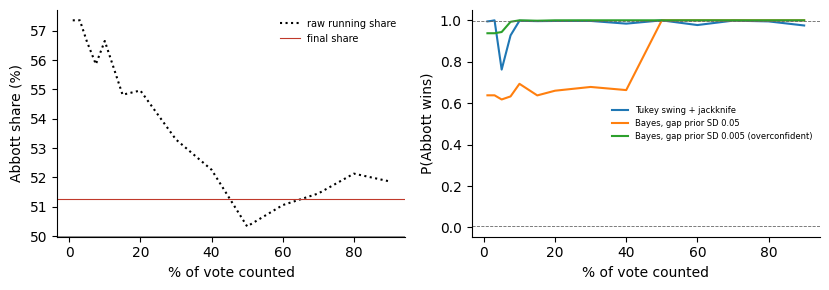

This night: true Abbott share 51.3%, raw share at 5% counted 56.6%


In [43]:
# one night: raw share and each method's P(Abbott)
N1 = make_night(7)
fig, ax = plt.subplots(1, 2, figsize=(8.4, 3.0))
raw = [(N1["nn"][r] * N1["y"][r]).sum() / N1["nn"][r].sum() for r in (reported(N1, f) for f in LOOKS)]
ax[0].plot(LOOKS * 100, np.array(raw) * 100, "k:", label="raw running share"); ax[0].axhline(N1["truth"] * 100, c=RED, lw=.8, label="final share")
ax[0].axhline(50, c=GREY, lw=.5); ax[0].set_xlabel("% of vote counted"); ax[0].set_ylabel("Abbott share (%)"); ax[0].legend(fontsize=7, frameon=False)
for lab, fn in METHODS.items():
    ax[1].plot(LOOKS * 100, [fn(N1, reported(N1, f)) for f in LOOKS], label=lab)
ax[1].axhline(CALL, c=GREY, ls="--", lw=.6); ax[1].axhline(1 - CALL, c=GREY, ls="--", lw=.6)
ax[1].set_xlabel("% of vote counted"); ax[1].set_ylabel("P(Abbott wins)"); ax[1].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()
print(f"This night: true Abbott share {N1['truth']*100:.1f}%, raw share at 5% counted {raw[3]*100:.1f}%")

**Reading the plot**

- Raw share starts far off (early, rural votes first).
- Tukey, overconfident Bayes: certain almost at once.
- Calibrated Bayes waits for election-day votes.

**Next cell**: 400 nights. Wrong call: the first call (either side) disagrees with the final winner. Share of nights called, median share counted at the call, wrong-call rate overall and in close races (final share within 2 points of 50%, a D minus R margin under 4 points).

In [44]:
# 400 nights: first call, right or wrong
rows = []
for seed in range(400):
    N = make_night(1000 + seed); win = N["truth"] > .5
    for lab, fn in METHODS.items():
        call_f, wrong = np.nan, False
        for f in LOOKS:
            P = fn(N, reported(N, f))
            if P >= CALL or P <= 1 - CALL:
                call_f, wrong = f, (P >= CALL) != win
                break
        rows.append(dict(method=lab, margin=abs(N["truth"] - .5), call_f=call_f, wrong=wrong))
nights = pd.DataFrame(rows)
nights["close"] = nights.margin < .02
summ = nights.groupby("method", sort=False).agg(nights=("wrong", "size"), called=("call_f", lambda s: s.notna().mean()),
                                               median_counted_at_call=("call_f", "median"), wrong_calls=("wrong", "mean"))
summ["wrong_in_close_races"] = nights[nights.close].groupby("method", sort=False).wrong.mean()
print(f"Close races (margin under 2 points of share): {int(nights[nights.method == list(METHODS)[0]].close.sum())} of 400")
show_table(summ.round(3), index=True)

# calibrated Bayes: median share counted at the call, by margin
bm = nights[nights.method == list(METHODS)[1]].copy()
bm["margin_bin"] = pd.cut(bm.margin * 100, [0, 1, 2, 4, 6, 20], labels=["0-1", "1-2", "2-4", "4-6", "6+"])
print("\nBayes with the calibrated gap prior: median share counted at the call, by margin (points of share)")
show_table(bm.groupby("margin_bin", observed=True).agg(nights=("call_f", "size"), median_counted=("call_f", "median"),
                                                  never_called=("call_f", lambda s: s.isna().mean())).round(3))

Close races (margin under 2 points of share): 203 of 400


,nights,called,median_counted_at_call,wrong_calls,wrong_in_close_races
method,,,,,
Tukey swing + jackknife,400,0.898,0.01,0.02,0.039
"Bayes, gap prior SD 0.05",400,0.995,0.5,0,0
"Bayes, gap prior SD 0.005 (overconfident)",400,0.998,0.01,0.02,0.039



Bayes with the calibrated gap prior: median share counted at the call, by margin (points of share)


,nights,median_counted,never_called
margin_bin,,,
0-1,98,0.6,0.02
1-2,105,0.5,0
2-4,135,0.5,0
4-6,50,0.5,0
6+,12,0.01,0


**Reading the result**

- Tukey: calls at 1% counted; wrong on 2% of nights, 3.9% of close races (nominal 0.5%). Unreported cells (election-day votes) borrow a zero-variance swing.
- Overconfident Bayes: same error rates. The fault is the prior, not Bayes.
- Calibrated Bayes: no wrong calls; median call at 50% counted.
- Floor: before election-day votes, only wins by 6 points of share (12 of margin) or more are callable early.
- Polson and Sokolov, 1,000 richer nights: Tukey wrong in 2.5% of races and 8.8% of close races; Bayesian systems no wrong calls.

**Evidence from New Zealand**

- Voting-place backtest, every New Zealand election 2005 to 2017, nights replayed in random reporting orders.
- **Reported, not recomputed**: Polson and Sokolov, "How Early Can an Election Be Called?". Voting-place data not in the course folder.

In [45]:
# REPORTED, not recomputed: backtest on New Zealand voting-place results, 2005 to 2017 (Polson and Sokolov,
# "How Early Can an Election Be Called?"). Needs nzelect data, not in the course folder.
# final_p = National share of the National + Labour vote; *_wrong = share of 200 replayed nights with a wrong call;
# bayes_called_at = share of the count at the call for the Bayes model with the anytime boundary (bayes_anytime_f in backtest.json; 1.0 = never called).
NZ = pd.DataFrame({"year": [2005, 2008, 2011, 2014, 2017],
                   "final_p": [.488, .569, .633, .652, .546],
                   "running_share_wrong": [.95, .015, .12, .015, .0],
                   "bayes_called_at": [1.0, .061, .027, .051, .064],
                   "bayes_wrong": [0, 0, 0, 0, 0]})
show_table(NZ, index=False)

year,final_p,running_share_wrong,bayes_called_at,bayes_wrong
2005,0.488,0.95,1,0
2008,0.569,0.015,0.061,0
2011,0.633,0.12,0.027,0
2014,0.652,0.015,0.051,0
2017,0.546,0,0.064,0


**Reading the table**

- 2005 (final National share 0.488): running share calls the wrong party on 95% of replayed nights (the TVNZ miscall).
- Bayes with the anytime boundary (`bayes_anytime_f` in `backtest.json`): never calls 2005 (too close); calls 2008 to 2017 at 3% to 6% of the count, no wrong calls.

### Exercise E.6: projected final share

- Project Abbott's final share from the partial count `E6` (votes in thousands; shares are Abbott's two-party share, 0 to 1).
- Per stratum $s$: swing $= \text{share\_now}_s - \text{share\_last}_s$; projected share of votes still out $= \text{last\_remaining}_s + \text{swing}_s$.
- $\text{share\_hat} = \sum_s (c_s\,\text{share\_now}_s + r_s\,\text{proj}_s)/\sum_s (c_s + r_s)$: counted votes $c_s$, remaining votes $r_s$ (`tukey` by hand).
- Define `share_hat` (0 to 1; 4 decimals).

In [ ]:
E6 = pd.DataFrame({
    "stratum": ["Urban", "Suburban", "Rural"],
    "counted": [400, 500, 700],                # votes counted so far, thousands
    "share_now": [0.40, 0.55, 0.72],           # Abbott share of the counted votes
    "share_last": [0.45, 0.58, 0.74],          # Abbott share of the same precincts in 2022
    "remaining": [600, 300, 100],              # votes still to count, thousands
    "last_remaining": [0.42, 0.57, 0.74],      # Abbott share in 2022 of the precincts still out
})
share_hat = None  # YOUR CODE

In [ ]:
check("share_hat", share_hat, "0c27d5f188bc26b6", ndigits=4)

## What to take away

- Before the close: center and spread. Texas, partial count (provisional): poll center too high for Abbott; market's wider spread scored better.
- One outcome cannot rank forecasters. Our 0.938 Senate control probability is probably overconfident (small shared error).
- Markets: close to calibrated, not strictly efficient. One race cannot settle who has the edge.
- After the close: a call is only as valid as the model of who reports first.
- Most often left out: the shared error (house effects, national swings, the early versus election-day gap).

## Submitting

- Do E.1 to E.6, then Kernel, Restart and Run All; save.
- Every code cell executed, outputs kept.
- Upload the `.ipynb` on Canvas before class on 11 November.
- `not yet` checks can be submitted; the answers count.